# Tema 2 Machine Learning - Images Classificator
## Mandescu Victor-Ioan 342C4

In [1]:
%pip install matplotlib
%pip install Pillow
%pip install torchvision
%pip install torch

from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch import device
from IPython import display
from sklearn.metrics import confusion_matrix

import time
import numpy as np
import os
import matplotlib.pyplot as plt
import random
import torch
import torchvision
import zipfile
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import seaborn as sns
import copy


In [2]:
path_to_zip_file = "/content/imagebits.zip"
directory_to_extract_to = "images"

if not os.path.exists(directory_to_extract_to):
    os.makedirs(directory_to_extract_to)

with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)

## Exploratory data analysis for image classification - imagebits

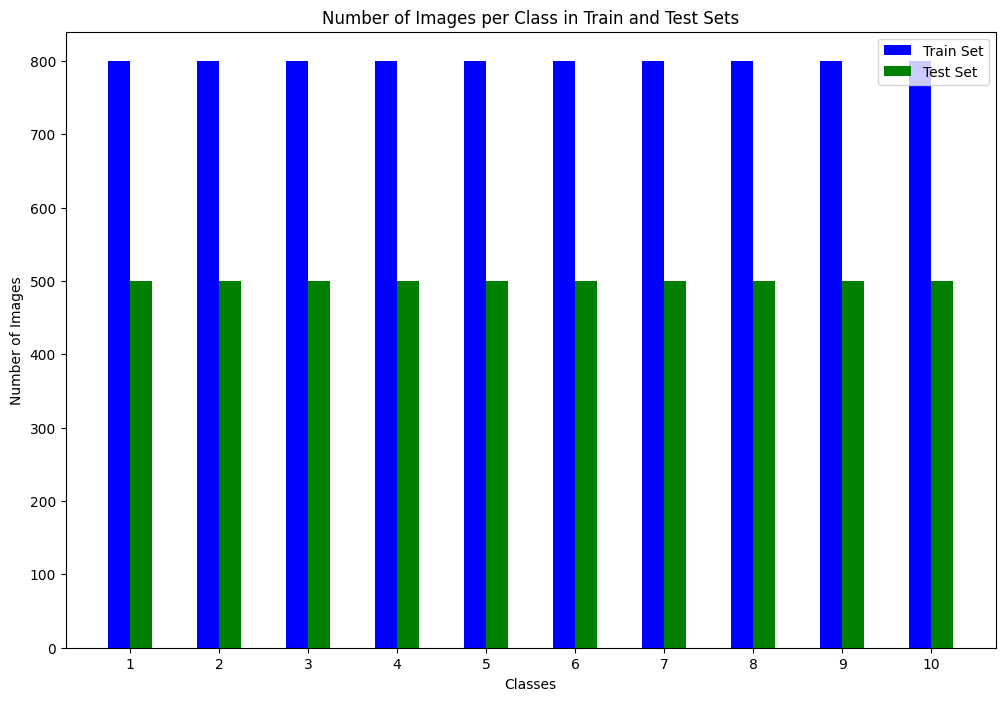

In [3]:
img_train_dir_path = 'images/imagebits/train/'
img_test_dir_path = 'images/imagebits/test/'
number_classes = {}

for i in range(1, 11):
    train_class_dir = os.path.join(img_train_dir_path, str(i))
    test_class_dir = os.path.join(img_test_dir_path, str(i))

    train_images = os.listdir(train_class_dir)
    test_images = os.listdir(test_class_dir)

    number_classes[i] = {'train_count': len(train_images), 'test_count': len(test_images)}

labels = list(number_classes.keys())
train_vals = []
test_vals = []

for v in number_classes.values():
    train_vals.append(v['train_count'])
    test_vals.append(v['test_count'])

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width/2, train_vals, width, label='Train Set', color='blue')
plt.bar(x + width/2, test_vals, width, label='Test Set', color='green')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train and Test Sets')
plt.xticks(x, labels)
plt.legend()
plt.show()

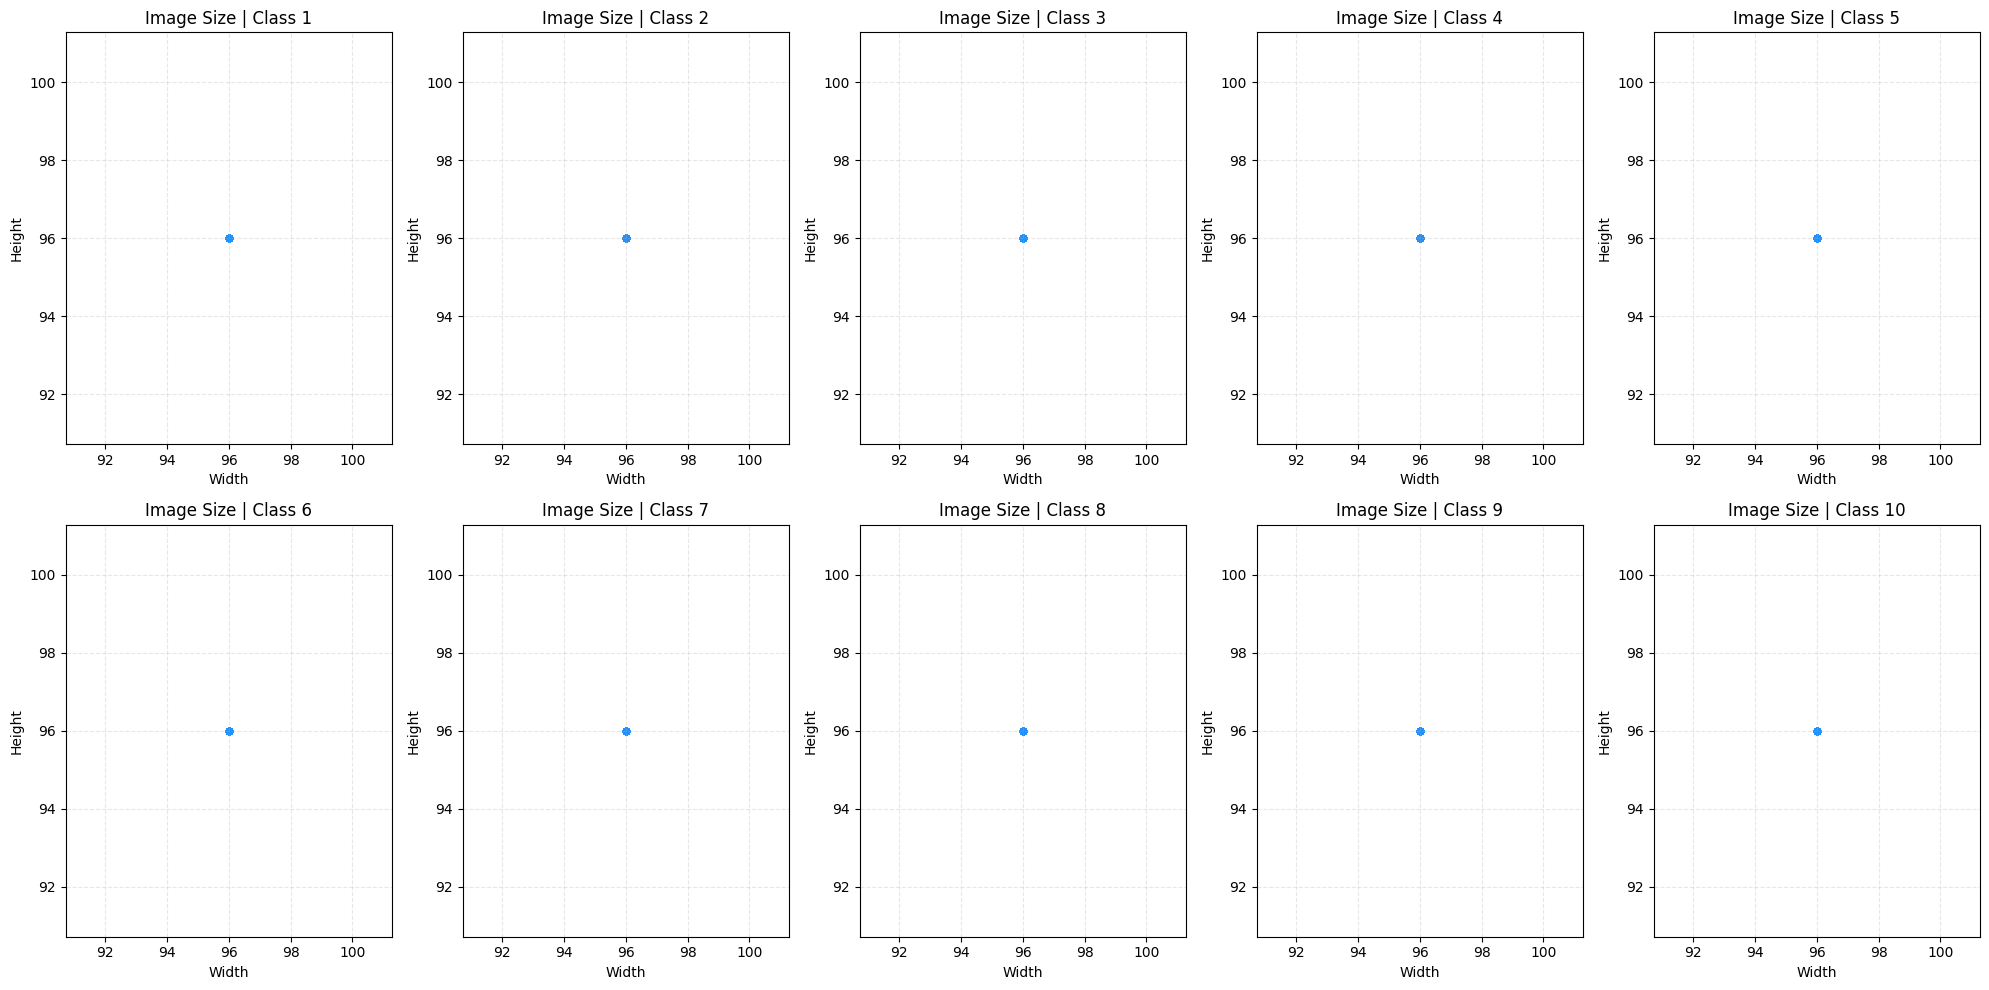

In [4]:
class_data = {}

for i in range(1, 11):
    class_dir = os.path.join(img_train_dir_path, str(i))
    images = os.listdir(class_dir)

    widths = []
    heights = []

    for img_name in images:
        if img_name.lower().endswith(('.png')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[i] = {'widths': widths, 'heights': heights}

fig, ax = plt.subplots(2, 5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    weight = class_data[class_id]['widths']
    height = class_data[class_id]['heights']

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].scatter(weight, height, alpha=0.5, s=20, color='dodgerblue')
    ax[row_idx, col_idx].set_title(f'Image Size | Class {class_id}')
    ax[row_idx, col_idx].set_xlabel('Width')
    ax[row_idx, col_idx].set_ylabel('Height')
    ax[row_idx, col_idx].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

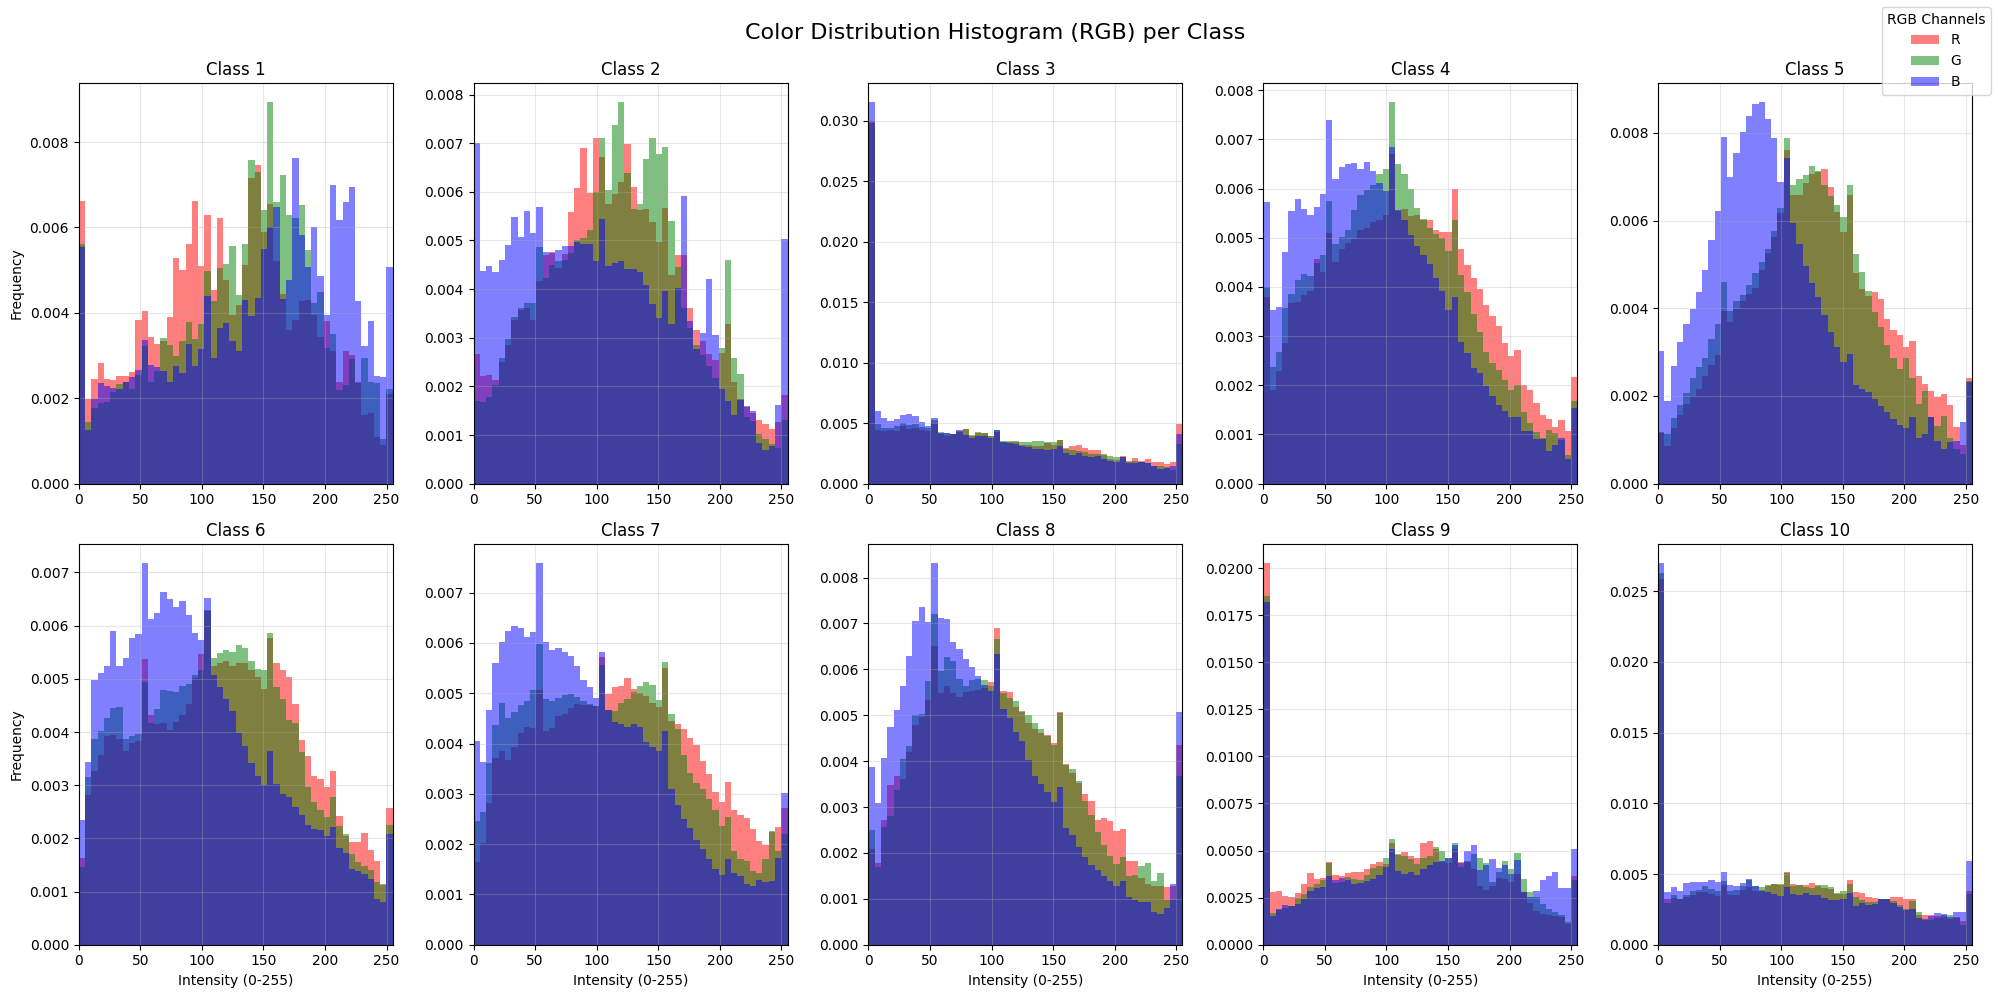

In [5]:
rgb_class = {}

for idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))

    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []

    for img_name in images:
        if img_name.lower().endswith(('.png')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())

    rgb_class[class_id] = { 'red': all_reds, 'green': all_greens, 'blue': all_blues }


fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    red = rgb_class[class_id]["red"]
    green = rgb_class[class_id]["green"]
    blue = rgb_class[class_id]["blue"]

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].hist(red, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax[row_idx, col_idx].hist(green, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax[row_idx, col_idx].hist(blue, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax[row_idx, col_idx].set_title(f'Class {class_id}')
    ax[row_idx, col_idx].set_xlim(0, 255)

    if idx % 5 == 0:
        ax[row_idx, col_idx].set_ylabel('Frequency')
    if idx >= 5:
        ax[row_idx, col_idx].set_xlabel('Intensity (0-255)')

    ax[row_idx, col_idx].grid(True, alpha=0.3)

handles, labels = ax[row_idx, col_idx].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) per Class", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

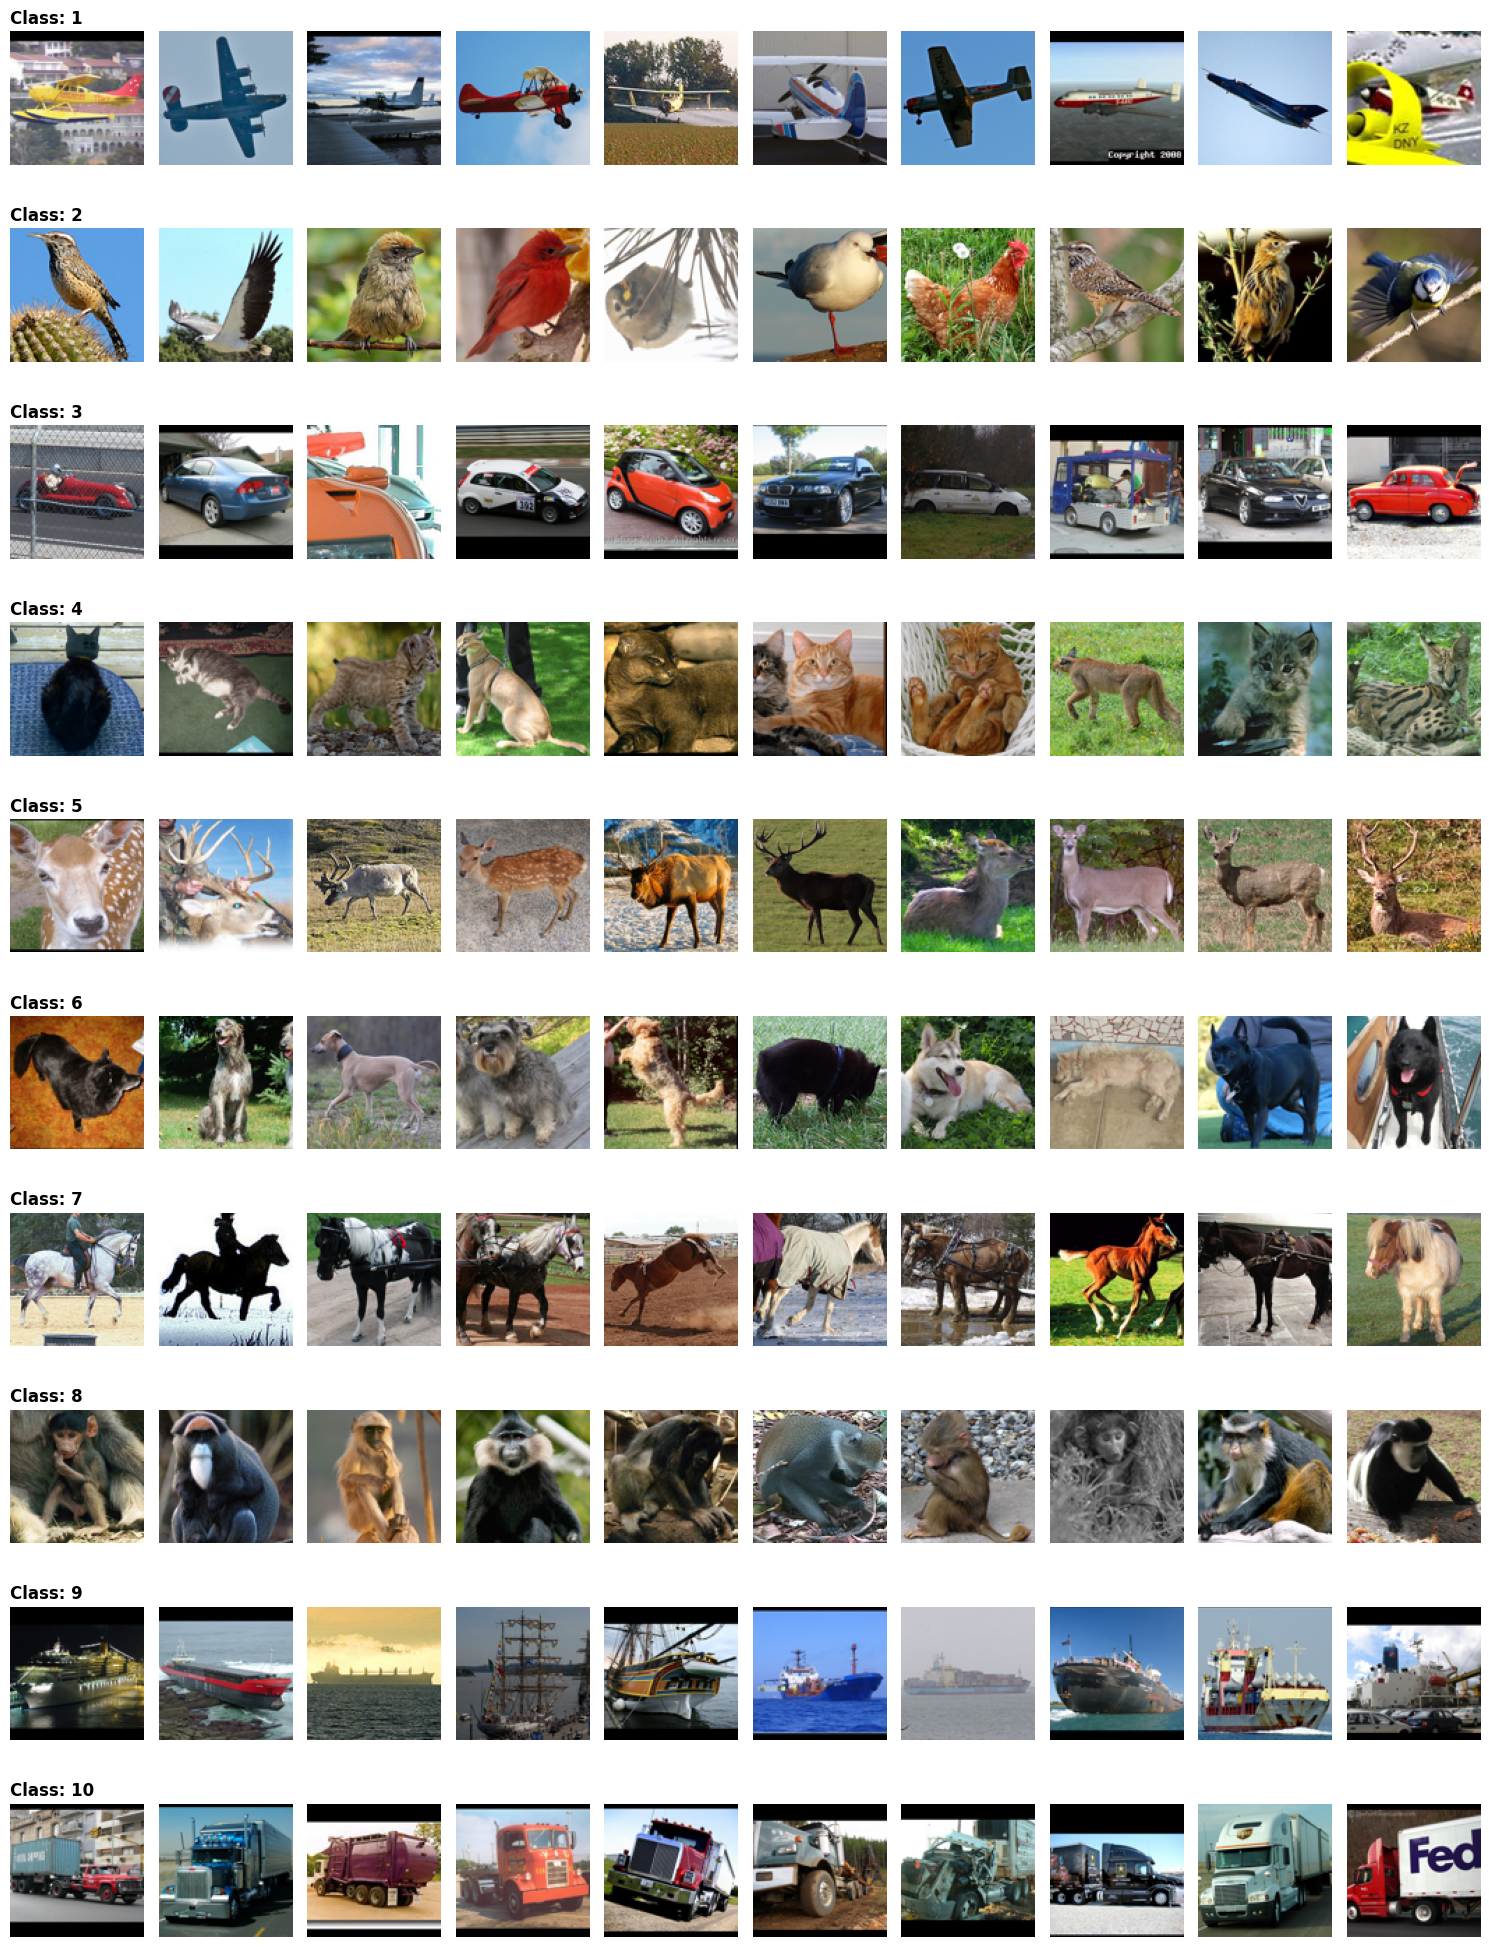

In [6]:
fig, ax = plt.subplots(10, 10, figsize=(15, 20))

for row_idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))
    all_imgs = []
    for f in os.listdir(class_dir):
      if f.lower().endswith(('.png')):
        all_imgs.append(f)

    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax[row_idx, col_idx].imshow(img)
            ax[row_idx, col_idx].axis('off')

            if col_idx == 0:
                ax[row_idx, col_idx].set_title(f'Class: {class_id}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [7]:
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print(f"Running on device: {device}")

train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_transform_aug = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images_aug = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform_aug)
train_images = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform)
test_images = torchvision.datasets.ImageFolder(root=img_test_dir_path, transform=test_transform)

print(f'Size of training labels {len(train_images.targets)}')
print(f'Size of test labels {len(test_images.targets)}')

Running on device: cuda
Size of training labels 8000
Size of test labels 5000


In [8]:
BATCH_SIZE_TRAIN = 64
BATCH_SIZE_TEST = 64
NO_WORKERS = 8
SHUFFLE_DATA = True

train_loader = torch.utils.data.DataLoader(train_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images, batch_train_labels) = next(iter(train_loader))

print(f'Shape of training images: {batch_train_images.size()}')
print(f'Shape of training labels: {batch_train_labels.size()}')

train_loader_aug = torch.utils.data.DataLoader(train_images_aug, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images_aug, batch_train_labels_aug) = next(iter(train_loader_aug))
print(f'Shape of augmented training images: {batch_train_images_aug.size()}')
print(f'Shape of augmented training labels: {batch_train_labels_aug.size()}')

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Shape of training images: torch.Size([64, 3, 96, 96])
Shape of training labels: torch.Size([64])
Shape of augmented training images: torch.Size([64, 3, 96, 96])
Shape of augmented training labels: torch.Size([64])


In [9]:
test_loader = torch.utils.data.DataLoader(test_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_images, batch_test_labels) = next(iter(test_loader))
print(f'Shape of test images: {batch_test_images.size()}')
print(f'Shape of test labels: {batch_test_labels.size()}')

Shape of test images: torch.Size([64, 3, 96, 96])
Shape of test labels: torch.Size([64])


In [10]:
def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.plot(steps, loss_list, c='b')
    time.sleep(1.0)

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k

In [11]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 96, hidden_size=512, out_size=256, num_classes=10):
        super(MLP, self).__init__()

        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, out_size)
        self.fc3 = nn.Linear(out_size, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [12]:
import torch
import torch.nn as nn

class MiniVGG(nn.Module):
    def __init__(self, num_classes=10, in_size=512, hidden_size1=1024, hidden_size2=1024, use_batch_norm=False, dropout_val=0.5):
        super(MiniVGG, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn1 = nn.BatchNorm2d(64)
        else:
            self.bn1 = nn.Identity()

        self.conv2 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn2 = nn.BatchNorm2d(64)
        else:
            self.bn2 = nn.Identity()

        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn3 = nn.BatchNorm2d(128)
        else:
            self.bn3 = nn.Identity()

        self.conv4 = nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn4 = nn.BatchNorm2d(128)
        else:
            self.bn4 = nn.Identity()

        self.conv5 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn5 = nn.BatchNorm2d(256)
        else:
            self.bn5 = nn.Identity()

        self.conv6 = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn6 = nn.BatchNorm2d(256)
        else:
            self.bn6 = nn.Identity()

        self.conv7 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn7 = nn.BatchNorm2d(512)
        else:
            self.bn7 = nn.Identity()

        self.conv8 = nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn8 = nn.BatchNorm2d(512)
        else:
            self.bn8 = nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        flatten_size = in_size * 7 * 7

        self.fc1 = nn.Linear(in_features=flatten_size, out_features=hidden_size1)
        self.fc2 = nn.Linear(in_features=hidden_size1, out_features=hidden_size2)
        self.fc3 = nn.Linear(in_features=hidden_size2, out_features=num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = self.relu(self.bn3(self.conv3(x)))
        x = self.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        x = self.relu(self.bn5(self.conv5(x)))
        x = self.relu(self.bn6(self.conv6(x)))
        x = self.pool(x)

        x = self.relu(self.bn7(self.conv7(x)))
        x = self.relu(self.bn8(self.conv8(x)))
        x = self.pool(x)

        x = self.avgpool(x)
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [13]:
EPOCHS = 50
TRAIN_ITERS = 100e3
REPORT_TRAIN_EVERY = 100
PLOT_EVERY = 100
REPORT_TEST_EVERY = 200
TEST_ITERS = 100

criterion = nn.CrossEntropyLoss()

def train_engine(net, train_data_loader, optimizer, scheduler, num_epochs=35, name="Experiment"):
    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    test_data_provider = loopy_test_loader(test_loader)

    net.train()

    for epoch in range(num_epochs):
        for i, data in enumerate(train_data_loader, 0):

            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_acc += top_k_accuracy(1, labels, outputs).item()

            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            if train_iter % REPORT_TEST_EVERY == 0:
                net.eval()
                with torch.no_grad():
                    test_iter = 0
                    test_loss_accum = 0.0
                    test_acc_accum = 0.0

                    while test_iter < TEST_ITERS:
                        try:
                            test_data = next(test_data_provider)
                        except StopIteration:
                            test_data_provider = loopy_test_loader(test_loader)
                            test_data = next(test_data_provider)

                        t_in, t_lbl = test_data[0].to(device), test_data[1].to(device)
                        t_out = net(t_in)

                        test_loss_accum += criterion(t_out, t_lbl).item()
                        test_acc_accum += top_k_accuracy(1, t_lbl, t_out).item()
                        test_iter += 1

                    avg_test_loss = test_loss_accum / TEST_ITERS
                    avg_test_acc = test_acc_accum / TEST_ITERS

                    print(f'>>> [{name} Val] Loss: {avg_test_loss:.5f}, Acc: {avg_test_acc:.2f}%')

                    history['val_loss'].append(avg_test_loss)
                    history['val_acc'].append(avg_test_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        scheduler.step()

    print(f"Finished: {name}")
    return history


Starting: Balanced_Adam_NoAug
>>> [Balanced_Adam_NoAug Val] Loss: 2.25193, Acc: 20.17%
[Balanced_Adam_NoAug] [Ep: 1, Step: 99] Train Loss: 2.01169, Acc: 25.94%
[Balanced_Adam_NoAug] [Ep: 2, Step: 199] Train Loss: 1.85972, Acc: 32.09%
>>> [Balanced_Adam_NoAug Val] Loss: 1.73049, Acc: 36.86%
[Balanced_Adam_NoAug] [Ep: 3, Step: 299] Train Loss: 1.75759, Acc: 34.88%
[Balanced_Adam_NoAug] [Ep: 4, Step: 399] Train Loss: 1.71748, Acc: 38.03%
>>> [Balanced_Adam_NoAug Val] Loss: 1.66773, Acc: 39.16%
[Balanced_Adam_NoAug] [Ep: 4, Step: 499] Train Loss: 1.67905, Acc: 38.62%
[Balanced_Adam_NoAug] [Ep: 5, Step: 599] Train Loss: 1.61731, Acc: 40.19%
>>> [Balanced_Adam_NoAug Val] Loss: 1.61490, Acc: 41.06%
[Balanced_Adam_NoAug] [Ep: 6, Step: 699] Train Loss: 1.59061, Acc: 41.98%
[Balanced_Adam_NoAug] [Ep: 7, Step: 799] Train Loss: 1.55658, Acc: 43.19%
>>> [Balanced_Adam_NoAug Val] Loss: 1.60003, Acc: 41.94%
[Balanced_Adam_NoAug] [Ep: 8, Step: 899] Train Loss: 1.51919, Acc: 45.19%
[Balanced_Adam_NoAu

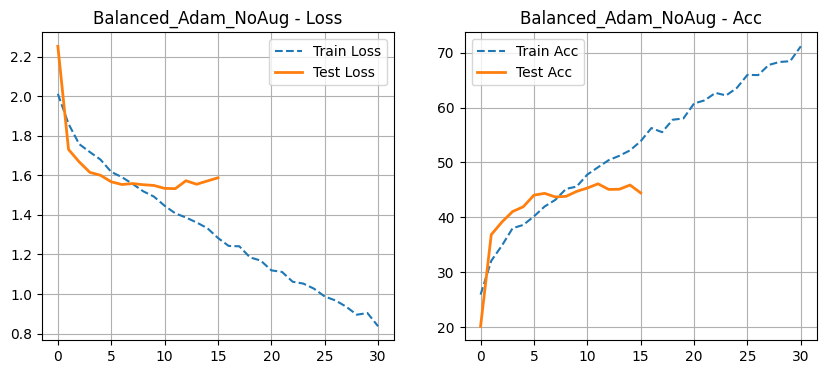


Starting: Classic_SGD_NoAug
>>> [Classic_SGD_NoAug Val] Loss: 2.28297, Acc: 16.77%
[Classic_SGD_NoAug] [Ep: 1, Step: 99] Train Loss: 2.29983, Acc: 15.94%
[Classic_SGD_NoAug] [Ep: 2, Step: 199] Train Loss: 2.31648, Acc: 10.27%
>>> [Classic_SGD_NoAug Val] Loss: 2.30334, Acc: 9.88%
[Classic_SGD_NoAug] [Ep: 3, Step: 299] Train Loss: 2.30258, Acc: 9.69%
[Classic_SGD_NoAug] [Ep: 4, Step: 399] Train Loss: 2.30845, Acc: 9.98%
>>> [Classic_SGD_NoAug Val] Loss: 2.30499, Acc: 10.16%
[Classic_SGD_NoAug] [Ep: 4, Step: 499] Train Loss: 2.30514, Acc: 10.25%
[Classic_SGD_NoAug] [Ep: 5, Step: 599] Train Loss: 2.30634, Acc: 9.95%
>>> [Classic_SGD_NoAug Val] Loss: 2.30329, Acc: 10.41%
[Classic_SGD_NoAug] [Ep: 6, Step: 699] Train Loss: 2.30451, Acc: 9.31%
[Classic_SGD_NoAug] [Ep: 7, Step: 799] Train Loss: 2.30683, Acc: 9.42%
>>> [Classic_SGD_NoAug Val] Loss: 2.30406, Acc: 9.73%
[Classic_SGD_NoAug] [Ep: 8, Step: 899] Train Loss: 2.30433, Acc: 10.00%
[Classic_SGD_NoAug] [Ep: 8, Step: 999] Train Loss: 2.307

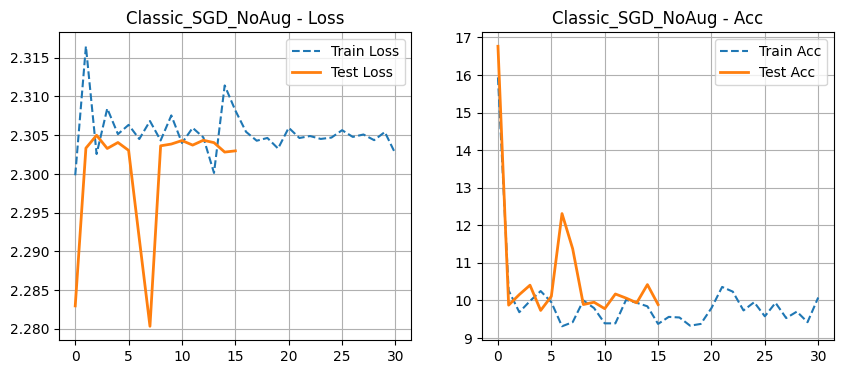


Starting: Wide_Slow_Adam_NoAug
>>> [Wide_Slow_Adam_NoAug Val] Loss: 2.29334, Acc: 14.03%
[Wide_Slow_Adam_NoAug] [Ep: 1, Step: 99] Train Loss: 2.06380, Acc: 26.05%
[Wide_Slow_Adam_NoAug] [Ep: 2, Step: 199] Train Loss: 1.86603, Acc: 32.47%
>>> [Wide_Slow_Adam_NoAug Val] Loss: 1.80463, Acc: 35.53%
[Wide_Slow_Adam_NoAug] [Ep: 3, Step: 299] Train Loss: 1.78619, Acc: 35.38%
[Wide_Slow_Adam_NoAug] [Ep: 4, Step: 399] Train Loss: 1.73913, Acc: 37.00%
>>> [Wide_Slow_Adam_NoAug Val] Loss: 1.70725, Acc: 38.56%
[Wide_Slow_Adam_NoAug] [Ep: 4, Step: 499] Train Loss: 1.69059, Acc: 39.69%
[Wide_Slow_Adam_NoAug] [Ep: 5, Step: 599] Train Loss: 1.65461, Acc: 39.81%
>>> [Wide_Slow_Adam_NoAug Val] Loss: 1.66157, Acc: 39.48%
[Wide_Slow_Adam_NoAug] [Ep: 6, Step: 699] Train Loss: 1.64139, Acc: 41.55%
[Wide_Slow_Adam_NoAug] [Ep: 7, Step: 799] Train Loss: 1.58824, Acc: 43.86%
>>> [Wide_Slow_Adam_NoAug Val] Loss: 1.63183, Acc: 40.08%
[Wide_Slow_Adam_NoAug] [Ep: 8, Step: 899] Train Loss: 1.56331, Acc: 43.92%
[Wid

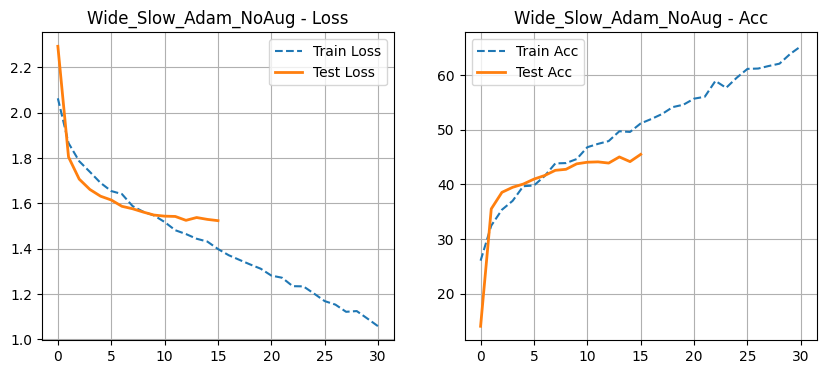


Starting: LongRun_Adam
>>> [LongRun_Adam Val] Loss: 2.28085, Acc: 15.70%
[LongRun_Adam] [Ep: 1, Step: 99] Train Loss: 2.15720, Acc: 22.22%
[LongRun_Adam] [Ep: 2, Step: 199] Train Loss: 2.05717, Acc: 25.58%
>>> [LongRun_Adam Val] Loss: 1.85037, Acc: 33.92%
[LongRun_Adam] [Ep: 3, Step: 299] Train Loss: 2.00378, Acc: 26.27%
[LongRun_Adam] [Ep: 4, Step: 399] Train Loss: 1.96130, Acc: 27.94%
>>> [LongRun_Adam Val] Loss: 1.78128, Acc: 35.47%
[LongRun_Adam] [Ep: 4, Step: 499] Train Loss: 1.94589, Acc: 28.27%
[LongRun_Adam] [Ep: 5, Step: 599] Train Loss: 1.92378, Acc: 28.48%
>>> [LongRun_Adam Val] Loss: 1.74862, Acc: 36.55%
[LongRun_Adam] [Ep: 6, Step: 699] Train Loss: 1.90067, Acc: 30.34%
[LongRun_Adam] [Ep: 7, Step: 799] Train Loss: 1.89996, Acc: 29.41%
>>> [LongRun_Adam Val] Loss: 1.73014, Acc: 37.55%
[LongRun_Adam] [Ep: 8, Step: 899] Train Loss: 1.87040, Acc: 31.03%
[LongRun_Adam] [Ep: 8, Step: 999] Train Loss: 1.86190, Acc: 31.17%
>>> [LongRun_Adam Val] Loss: 1.72700, Acc: 36.98%
[LongRu

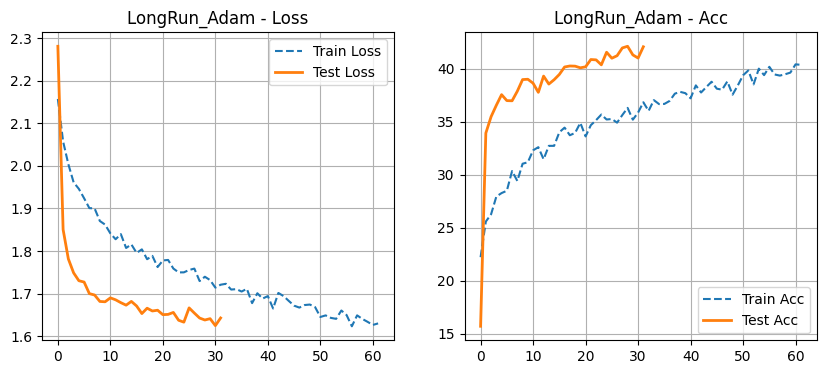


Starting: Patience_SGD
>>> [Patience_SGD Val] Loss: 2.29703, Acc: 12.55%
[Patience_SGD] [Ep: 1, Step: 99] Train Loss: 2.11330, Acc: 21.14%
[Patience_SGD] [Ep: 2, Step: 199] Train Loss: 1.97816, Acc: 26.44%
>>> [Patience_SGD Val] Loss: 1.83097, Acc: 32.42%
[Patience_SGD] [Ep: 3, Step: 299] Train Loss: 1.93904, Acc: 28.42%
[Patience_SGD] [Ep: 4, Step: 399] Train Loss: 1.92174, Acc: 28.34%
>>> [Patience_SGD Val] Loss: 1.79484, Acc: 33.03%
[Patience_SGD] [Ep: 4, Step: 499] Train Loss: 1.92845, Acc: 27.19%
[Patience_SGD] [Ep: 5, Step: 599] Train Loss: 1.89442, Acc: 29.19%
>>> [Patience_SGD Val] Loss: 1.77485, Acc: 34.08%
[Patience_SGD] [Ep: 6, Step: 699] Train Loss: 1.88970, Acc: 30.27%
[Patience_SGD] [Ep: 7, Step: 799] Train Loss: 1.88719, Acc: 29.20%
>>> [Patience_SGD Val] Loss: 1.76948, Acc: 35.66%
[Patience_SGD] [Ep: 8, Step: 899] Train Loss: 1.85223, Acc: 30.98%
[Patience_SGD] [Ep: 8, Step: 999] Train Loss: 1.87535, Acc: 30.16%
>>> [Patience_SGD Val] Loss: 1.75490, Acc: 34.64%
[Patien

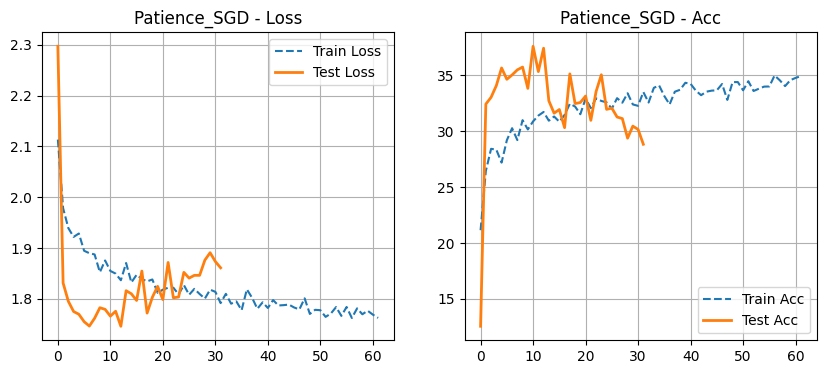


Starting: Aggressive_Adam
>>> [Aggressive_Adam Val] Loss: 2.24959, Acc: 18.08%
[Aggressive_Adam] [Ep: 1, Step: 99] Train Loss: 2.09635, Acc: 22.88%
[Aggressive_Adam] [Ep: 2, Step: 199] Train Loss: 1.97215, Acc: 27.38%
>>> [Aggressive_Adam Val] Loss: 1.79823, Acc: 34.55%
[Aggressive_Adam] [Ep: 3, Step: 299] Train Loss: 1.92752, Acc: 28.48%
[Aggressive_Adam] [Ep: 4, Step: 399] Train Loss: 1.88713, Acc: 30.33%
>>> [Aggressive_Adam Val] Loss: 1.73853, Acc: 36.89%
[Aggressive_Adam] [Ep: 4, Step: 499] Train Loss: 1.85588, Acc: 32.12%
[Aggressive_Adam] [Ep: 5, Step: 599] Train Loss: 1.85211, Acc: 31.05%
>>> [Aggressive_Adam Val] Loss: 1.75010, Acc: 35.33%
[Aggressive_Adam] [Ep: 6, Step: 699] Train Loss: 1.81150, Acc: 32.70%
[Aggressive_Adam] [Ep: 7, Step: 799] Train Loss: 1.79549, Acc: 33.81%
>>> [Aggressive_Adam Val] Loss: 1.70025, Acc: 37.89%
[Aggressive_Adam] [Ep: 8, Step: 899] Train Loss: 1.78354, Acc: 33.77%
[Aggressive_Adam] [Ep: 8, Step: 999] Train Loss: 1.78374, Acc: 34.03%
>>> [Aggr

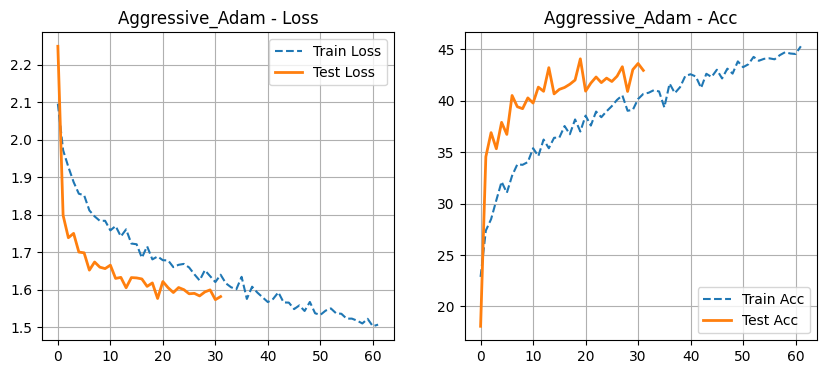

In [14]:
experiments = [
    {
        "name": "Balanced_Adam_NoAug",
        "hidden": 1024,
        "out": 256,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 1e-3,
        "augmentation": False
    },
    {
        "name": "Classic_SGD_NoAug",
        "hidden": 512,
        "out": 128,
        "opt": "sgd",
        "lr": 0.05,
        "wd": 5e-4,
        "augmentation": False
    },
    {
        "name": "Wide_Slow_Adam_NoAug",
        "hidden": 2048,
        "out": 512,
        "opt": "adam",
        "lr": 1e-5,
        "wd": 1e-4,
        "augmentation": False
    },
    {
        "name": "LongRun_Adam",
        "hidden": 1024,
        "out": 256,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 0,
        "augmentation": True
    },
    {
        "name": "Patience_SGD",
        "hidden": 2048,
        "out": 512,
        "opt": "sgd",
        "lr": 0.01,
        "wd": 1e-5,
        "augmentation": True
    },
    {
        "name": "Aggressive_Adam",
        "hidden": 4096,
        "out": 1024,
        "opt": "adam",
        "lr": 0.00005,
        "wd": 1e-5,
        "augmentation": True
    }
]

results_table = []
best_acc = 0.0
best_model_state = None
best_model_name = ""
best_config_hidden = 0
best_config_out = 0

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = MLP(img_size=96, hidden_size=exp['hidden'], out_size=exp['out'], num_classes=10).to(device)

    if exp['opt'] == 'adam':
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])
    elif exp['opt'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=exp['wd'])

    if exp['augmentation']:
        loader = train_loader_aug
        num_epochs = 50
    else:
        loader = train_loader
        num_epochs = 25

    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[2000, 3000], gamma=0.1)

    hist = train_engine(net, loader, optimizer, scheduler, num_epochs=num_epochs, name=exp['name'])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Test Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Test Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]
    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()

    results_table.append({
        "Model": exp['name'],
        "Hidden Size": exp['hidden'],
        "Out Size": exp['out'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['opt'],
        "LR": exp['lr'],
        "Final Val Acc": f"{final_acc:.2f}%",
        "Final Val Loss": f"{final_loss:.4f}"
    })

    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config_hidden = exp['hidden']
        best_config_out = exp['out']
        best_model_state = copy.deepcopy(net.state_dict())


Final results:


,Model,Hidden Size,Out Size,Augmentation,Optimizator,LR,Final Val Acc,Final Val Loss
0,Balanced_Adam_NoAug,1024,256,False,adam,0.00010,44.45%,1.5876
1,Classic_SGD_NoAug,512,128,False,sgd,0.05000,9.89%,2.3030
2,Wide_Slow_Adam_NoAug,2048,512,False,adam,0.00001,45.52%,1.5239
3,LongRun_Adam,1024,256,True,adam,0.00010,42.06%,1.6426
4,Patience_SGD,2048,512,True,sgd,0.01000,28.83%,1.8609
5,Aggressive_Adam,4096,1024,True,adam,0.00005,42.94%,1.5814



Confusion Matrix for: Wide_Slow_Adam_NoAug (Acc: 45.52%)


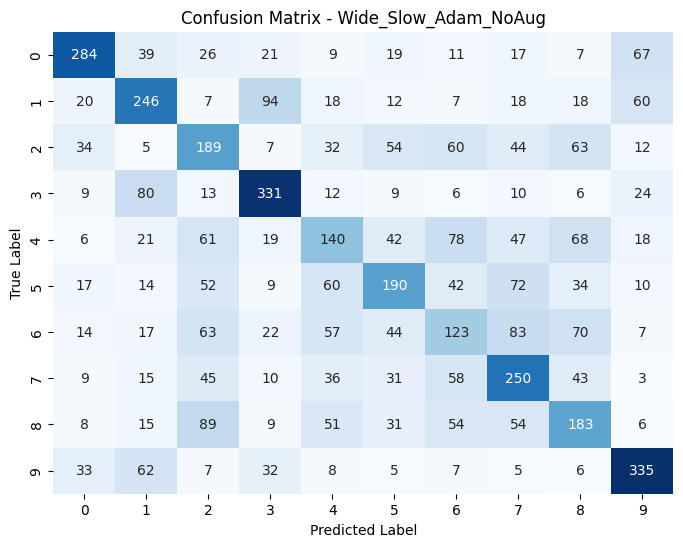


Best model: Wide_Slow_Adam_NoAug with 45.52% accuracy


In [15]:
print("\nFinal results:")
df = pd.DataFrame(results_table)
display.display(df)

print(f"\nConfusion Matrix for: {best_model_name} (Acc: {best_acc:.2f}%)")

final_net = MLP(img_size=96, hidden_size=best_config_hidden, out_size=best_config_out, num_classes=10).to(device)
final_net.load_state_dict(best_model_state)
final_net.eval()

all_preds = []
all_labels = []

final_test_loader = torch.utils.data.DataLoader(test_images, batch_size=64, shuffle=False, num_workers=2)

with torch.no_grad():
    for inputs, labels in final_test_loader:
        inputs = inputs.to(device)
        outputs = final_net(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

print(f"\nBest model: {best_model_name} with {best_acc:.2f}% accuracy")


Starting: VGG_Heavy_Adam


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


>>> [VGG_Heavy_Adam Val] Loss: 2.30292, Acc: 10.09%
[VGG_Heavy_Adam] [Ep: 1, Step: 99] Train Loss: 1.90801, Acc: 28.11%
[VGG_Heavy_Adam] [Ep: 2, Step: 199] Train Loss: 1.52692, Acc: 40.92%
>>> [VGG_Heavy_Adam Val] Loss: 1.33460, Acc: 48.17%
[VGG_Heavy_Adam] [Ep: 3, Step: 299] Train Loss: 1.35943, Acc: 47.88%
[VGG_Heavy_Adam] [Ep: 4, Step: 399] Train Loss: 1.21366, Acc: 55.33%
>>> [VGG_Heavy_Adam Val] Loss: 1.11649, Acc: 60.28%
[VGG_Heavy_Adam] [Ep: 4, Step: 499] Train Loss: 1.09514, Acc: 59.61%
[VGG_Heavy_Adam] [Ep: 5, Step: 599] Train Loss: 0.97284, Acc: 64.92%
>>> [VGG_Heavy_Adam Val] Loss: 1.00865, Acc: 63.25%
[VGG_Heavy_Adam] [Ep: 6, Step: 699] Train Loss: 0.89145, Acc: 67.80%
[VGG_Heavy_Adam] [Ep: 7, Step: 799] Train Loss: 0.81983, Acc: 70.16%
>>> [VGG_Heavy_Adam Val] Loss: 1.44386, Acc: 55.06%
[VGG_Heavy_Adam] [Ep: 8, Step: 899] Train Loss: 0.76299, Acc: 72.67%
[VGG_Heavy_Adam] [Ep: 8, Step: 999] Train Loss: 0.71438, Acc: 74.16%
>>> [VGG_Heavy_Adam Val] Loss: 0.87883, Acc: 69.22%

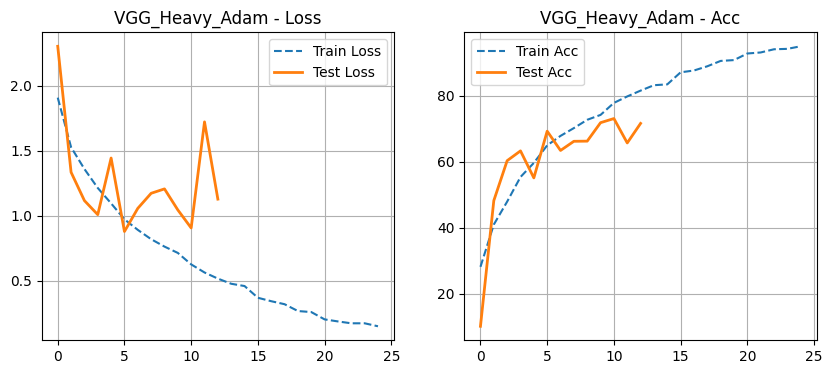


Starting: 2_VGG_Heavy_SGD
>>> [2_VGG_Heavy_SGD Val] Loss: 2.30253, Acc: 10.27%
[2_VGG_Heavy_SGD] [Ep: 1, Step: 99] Train Loss: 1.85787, Acc: 28.77%
[2_VGG_Heavy_SGD] [Ep: 2, Step: 199] Train Loss: 1.54794, Acc: 39.98%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.48538, Acc: 44.06%
[2_VGG_Heavy_SGD] [Ep: 3, Step: 299] Train Loss: 1.42244, Acc: 46.77%
[2_VGG_Heavy_SGD] [Ep: 4, Step: 399] Train Loss: 1.32635, Acc: 51.77%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.36473, Acc: 46.02%
[2_VGG_Heavy_SGD] [Ep: 4, Step: 499] Train Loss: 1.22663, Acc: 55.03%
[2_VGG_Heavy_SGD] [Ep: 5, Step: 599] Train Loss: 1.13714, Acc: 58.28%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.08777, Acc: 60.55%
[2_VGG_Heavy_SGD] [Ep: 6, Step: 699] Train Loss: 1.05345, Acc: 62.02%
[2_VGG_Heavy_SGD] [Ep: 7, Step: 799] Train Loss: 0.97316, Acc: 65.58%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.17416, Acc: 58.61%
[2_VGG_Heavy_SGD] [Ep: 8, Step: 899] Train Loss: 0.95420, Acc: 65.56%
[2_VGG_Heavy_SGD] [Ep: 8, Step: 999] Train Loss: 0.90272, Acc: 68.34%
>>> [2_VG

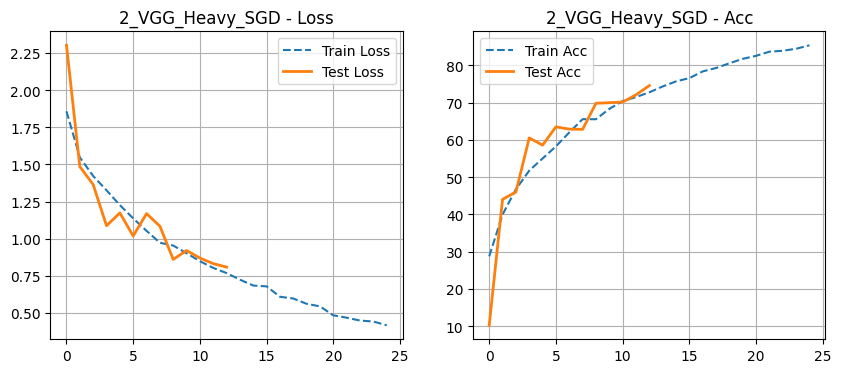


Starting: VGG_Medium_Adam
>>> [VGG_Medium_Adam Val] Loss: 2.30305, Acc: 10.12%
[VGG_Medium_Adam] [Ep: 1, Step: 99] Train Loss: 1.89288, Acc: 27.95%
[VGG_Medium_Adam] [Ep: 2, Step: 199] Train Loss: 1.52497, Acc: 41.62%
>>> [VGG_Medium_Adam Val] Loss: 1.35691, Acc: 50.09%
[VGG_Medium_Adam] [Ep: 3, Step: 299] Train Loss: 1.36581, Acc: 48.70%
[VGG_Medium_Adam] [Ep: 4, Step: 399] Train Loss: 1.23093, Acc: 54.86%
>>> [VGG_Medium_Adam Val] Loss: 1.33488, Acc: 52.98%
[VGG_Medium_Adam] [Ep: 4, Step: 499] Train Loss: 1.08482, Acc: 59.80%
[VGG_Medium_Adam] [Ep: 5, Step: 599] Train Loss: 1.00341, Acc: 63.38%
>>> [VGG_Medium_Adam Val] Loss: 1.00337, Acc: 63.19%
[VGG_Medium_Adam] [Ep: 6, Step: 699] Train Loss: 0.91207, Acc: 67.38%
[VGG_Medium_Adam] [Ep: 7, Step: 799] Train Loss: 0.83290, Acc: 70.50%
>>> [VGG_Medium_Adam Val] Loss: 1.15722, Acc: 61.27%
[VGG_Medium_Adam] [Ep: 8, Step: 899] Train Loss: 0.79199, Acc: 71.81%
[VGG_Medium_Adam] [Ep: 8, Step: 999] Train Loss: 0.70883, Acc: 75.20%
>>> [VGG_

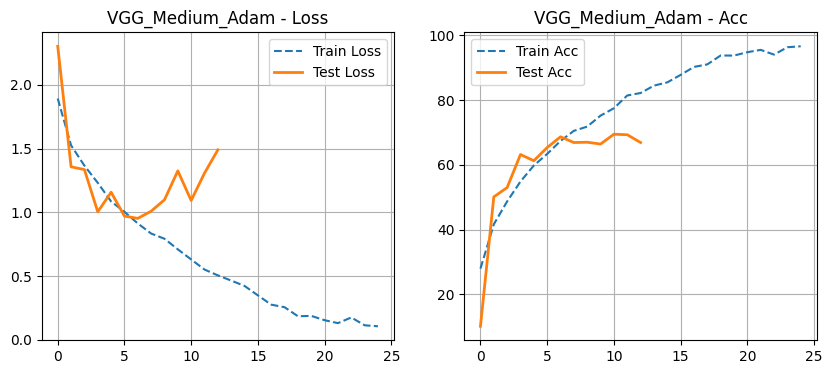


Starting: VGG_FullPower_Adam
>>> [VGG_FullPower_Adam Val] Loss: 2.30362, Acc: 10.19%
[VGG_FullPower_Adam] [Ep: 1, Step: 99] Train Loss: 2.66743, Acc: 15.81%
[VGG_FullPower_Adam] [Ep: 2, Step: 199] Train Loss: 1.92661, Acc: 25.98%
>>> [VGG_FullPower_Adam Val] Loss: 1.77610, Acc: 31.61%
[VGG_FullPower_Adam] [Ep: 3, Step: 299] Train Loss: 1.75654, Acc: 29.66%
[VGG_FullPower_Adam] [Ep: 4, Step: 399] Train Loss: 1.72218, Acc: 31.05%
>>> [VGG_FullPower_Adam Val] Loss: 1.55049, Acc: 38.47%
[VGG_FullPower_Adam] [Ep: 4, Step: 499] Train Loss: 1.66153, Acc: 33.66%
[VGG_FullPower_Adam] [Ep: 5, Step: 599] Train Loss: 1.61432, Acc: 37.34%
>>> [VGG_FullPower_Adam Val] Loss: 1.51845, Acc: 39.61%
[VGG_FullPower_Adam] [Ep: 6, Step: 699] Train Loss: 1.54494, Acc: 41.08%
[VGG_FullPower_Adam] [Ep: 7, Step: 799] Train Loss: 1.52982, Acc: 41.28%
>>> [VGG_FullPower_Adam Val] Loss: 1.43681, Acc: 44.77%
[VGG_FullPower_Adam] [Ep: 8, Step: 899] Train Loss: 1.48888, Acc: 42.77%
[VGG_FullPower_Adam] [Ep: 8, Step:

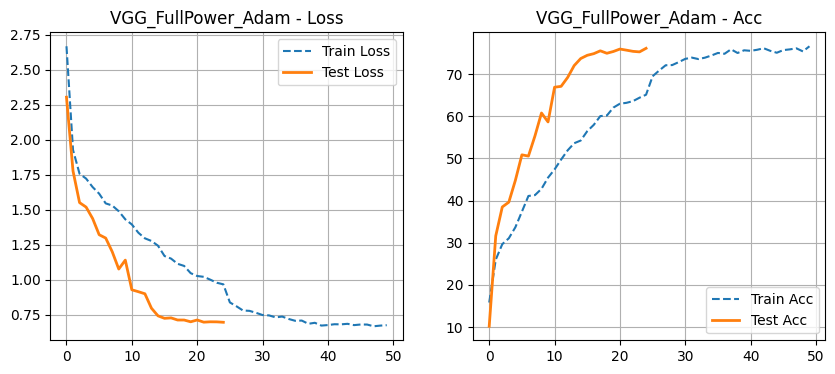


Starting: VGG_Classic_SGD_Aug
>>> [VGG_Classic_SGD_Aug Val] Loss: 2.30281, Acc: 9.72%
[VGG_Classic_SGD_Aug] [Ep: 1, Step: 99] Train Loss: 1.93703, Acc: 26.12%
[VGG_Classic_SGD_Aug] [Ep: 2, Step: 199] Train Loss: 1.66961, Acc: 35.50%
>>> [VGG_Classic_SGD_Aug Val] Loss: 1.52354, Acc: 43.05%
[VGG_Classic_SGD_Aug] [Ep: 3, Step: 299] Train Loss: 1.55734, Acc: 40.11%
[VGG_Classic_SGD_Aug] [Ep: 4, Step: 399] Train Loss: 1.48602, Acc: 44.11%
>>> [VGG_Classic_SGD_Aug Val] Loss: 1.47409, Acc: 46.12%
[VGG_Classic_SGD_Aug] [Ep: 4, Step: 499] Train Loss: 1.38697, Acc: 49.62%
[VGG_Classic_SGD_Aug] [Ep: 5, Step: 599] Train Loss: 1.32041, Acc: 50.73%
>>> [VGG_Classic_SGD_Aug Val] Loss: 1.23571, Acc: 53.83%
[VGG_Classic_SGD_Aug] [Ep: 6, Step: 699] Train Loss: 1.27242, Acc: 54.14%
[VGG_Classic_SGD_Aug] [Ep: 7, Step: 799] Train Loss: 1.22532, Acc: 54.77%
>>> [VGG_Classic_SGD_Aug Val] Loss: 1.27413, Acc: 55.09%
[VGG_Classic_SGD_Aug] [Ep: 8, Step: 899] Train Loss: 1.20446, Acc: 57.16%
[VGG_Classic_SGD_Aug

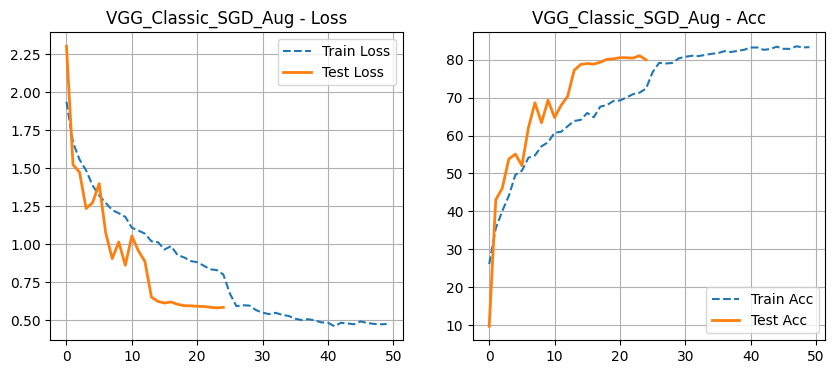


Starting: VGG_SlowBurn_Adam
>>> [VGG_SlowBurn_Adam Val] Loss: 2.30296, Acc: 9.91%
[VGG_SlowBurn_Adam] [Ep: 1, Step: 99] Train Loss: 2.03674, Acc: 24.22%
[VGG_SlowBurn_Adam] [Ep: 2, Step: 199] Train Loss: 1.69551, Acc: 35.67%
>>> [VGG_SlowBurn_Adam Val] Loss: 1.52079, Acc: 44.02%
[VGG_SlowBurn_Adam] [Ep: 3, Step: 299] Train Loss: 1.56406, Acc: 39.75%
[VGG_SlowBurn_Adam] [Ep: 4, Step: 399] Train Loss: 1.47787, Acc: 44.12%
>>> [VGG_SlowBurn_Adam Val] Loss: 1.33325, Acc: 50.86%
[VGG_SlowBurn_Adam] [Ep: 4, Step: 499] Train Loss: 1.40063, Acc: 47.75%
[VGG_SlowBurn_Adam] [Ep: 5, Step: 599] Train Loss: 1.34101, Acc: 50.28%
>>> [VGG_SlowBurn_Adam Val] Loss: 1.23704, Acc: 54.48%
[VGG_SlowBurn_Adam] [Ep: 6, Step: 699] Train Loss: 1.29483, Acc: 52.50%
[VGG_SlowBurn_Adam] [Ep: 7, Step: 799] Train Loss: 1.25147, Acc: 54.48%
>>> [VGG_SlowBurn_Adam Val] Loss: 1.18593, Acc: 56.84%
[VGG_SlowBurn_Adam] [Ep: 8, Step: 899] Train Loss: 1.19916, Acc: 56.16%
[VGG_SlowBurn_Adam] [Ep: 8, Step: 999] Train Loss:

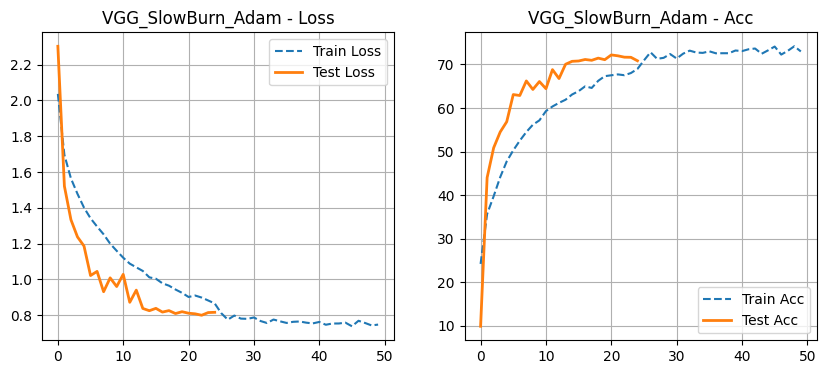

In [16]:
experiments = [
    {
        "name": "VGG_Heavy_Adam",
        "input": 512,
        "hidden1": 4096,
        "hidden2": 1024,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 1e-4,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": False
    },
    {
        "name": "2_VGG_Heavy_SGD",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 2048,
        "opt": "sgd",
        "lr": 0.01,
        "momentum": 0.9,
        "wd": 5e-4,
        "batch_norm": True,
        "dropout_val": 0.4,
        "augmentation": False
    },
    {
        "name": "VGG_Medium_Adam",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 512,
        "opt": "adam",
        "lr": 0.00005,
        "wd": 1e-5,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": False
    }, {
        "name": "VGG_FullPower_Adam",
        "input": 512,
        "hidden1": 4096,
        "hidden2": 4096,
        "opt": "adam",
        "lr": 0.0003,
        "wd": 1e-5,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": True
    },
    {
        "name": "VGG_Classic_SGD_Aug",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 1024,
        "opt": "sgd",
        "lr": 0.01,
        "momentum": 0.9,
        "wd": 1e-4,
        "batch_norm": True,
        "dropout_val": 0.4,
        "augmentation": True
    },
    {
        "name": "VGG_SlowBurn_Adam",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 512,
        "opt": "adam",
        "lr": 0.00001,
        "wd": 0,
        "batch_norm": True,
        "dropout_val": 0.3,
        "augmentation": True
    }

]

results_table = []
best_acc = 0.0
best_model_state = None
best_model_name = ""
best_config = {}

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = MiniVGG(num_classes=10, in_size=exp['input'], hidden_size1=exp['hidden1'], hidden_size2=exp['hidden2'],
                  use_batch_norm=exp['batch_norm'], dropout_val=exp['dropout_val']).to(device)

    if exp['augmentation']:
        loader = train_loader_aug
        num_epochs = 40
    else:
        loader = train_loader
        num_epochs = 20

    if exp['opt'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=exp['momentum'], weight_decay=exp['wd'])
    elif exp['opt'] == 'adam':
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])

    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[20, 30], gamma=0.1)

    hist = train_engine(net, loader, optimizer, scheduler, num_epochs=num_epochs, name=exp['name'])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Test Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Test Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()
    if torch.is_tensor(final_loss):
        final_loss = final_loss.item()

    results_table.append({
        "Model": exp['name'],
        "Hidden1": exp['hidden1'],
        "Hidden2": exp['hidden2'],
        "BatchNorm": exp['batch_norm'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['opt'],
        "LR": exp['lr'],
        "Final Val Acc": f"{final_acc:.2f}%",
        "Final Val Loss": f"{final_loss:.4f}"
    })

    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config = exp.copy()
        best_model_state = copy.deepcopy(net.state_dict())


Final results:


,Model,Hidden1,Hidden2,BatchNorm,Augmentation,Optimizator,LR,Final Val Acc,Final Val Loss
0,VGG_Heavy_Adam,4096,1024,True,False,adam,0.00010,71.58%,1.1279
1,2_VGG_Heavy_SGD,2048,2048,True,False,sgd,0.01000,74.59%,0.8093
2,VGG_Medium_Adam,2048,512,True,False,adam,0.00005,66.89%,1.4899
3,VGG_FullPower_Adam,4096,4096,True,True,adam,0.00030,76.08%,0.6956
4,VGG_Classic_SGD_Aug,2048,1024,True,True,sgd,0.01000,79.97%,0.5849
5,VGG_SlowBurn_Adam,2048,512,True,True,adam,0.00001,70.83%,0.8153



Confusion Matrix for: VGG_Classic_SGD_Aug (Acc: 79.97%)


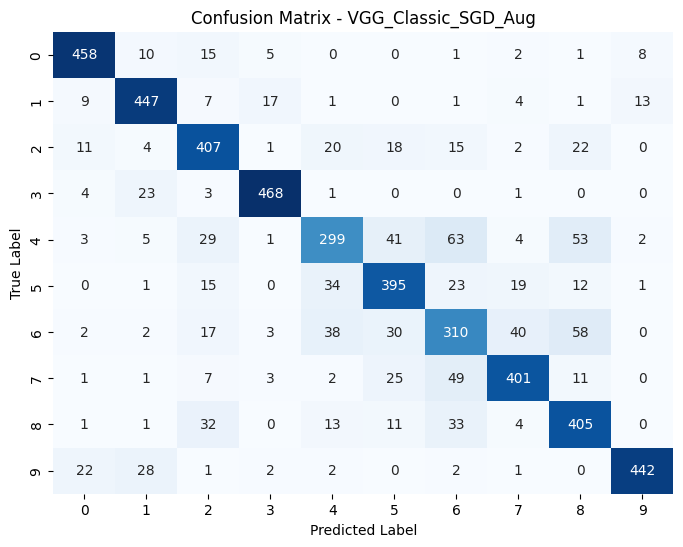


Best model: VGG_Classic_SGD_Aug with 79.97% accuracy


In [17]:
print("\nFinal results:")
df = pd.DataFrame(results_table)
display.display(df)

print(f"\nConfusion Matrix for: {best_model_name} (Acc: {best_acc:.2f}%)")

final_net = MiniVGG(num_classes=10, in_size=best_config['input'], hidden_size1=best_config['hidden1'], hidden_size2=best_config['hidden2'],
                    use_batch_norm=best_config['batch_norm'], dropout_val=best_config['dropout_val']).to(device)

final_net.load_state_dict(best_model_state)
final_net.eval()

all_preds = []
all_labels = []

final_test_loader = torch.utils.data.DataLoader(test_images, batch_size=64, shuffle=False, num_workers=2)

with torch.no_grad():
    for inputs, labels in final_test_loader:
        inputs = inputs.to(device)
        outputs = final_net(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

print(f"\nBest model: {best_model_name} with {best_acc:.2f}% accuracy")

In [18]:
path_to_zip_file = "/content/land_patches.zip"
directory_to_extract_to = "images"

if not os.path.exists(directory_to_extract_to):
    os.makedirs(directory_to_extract_to)

with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)

## Exploratory data analysis for image classification - land_patches

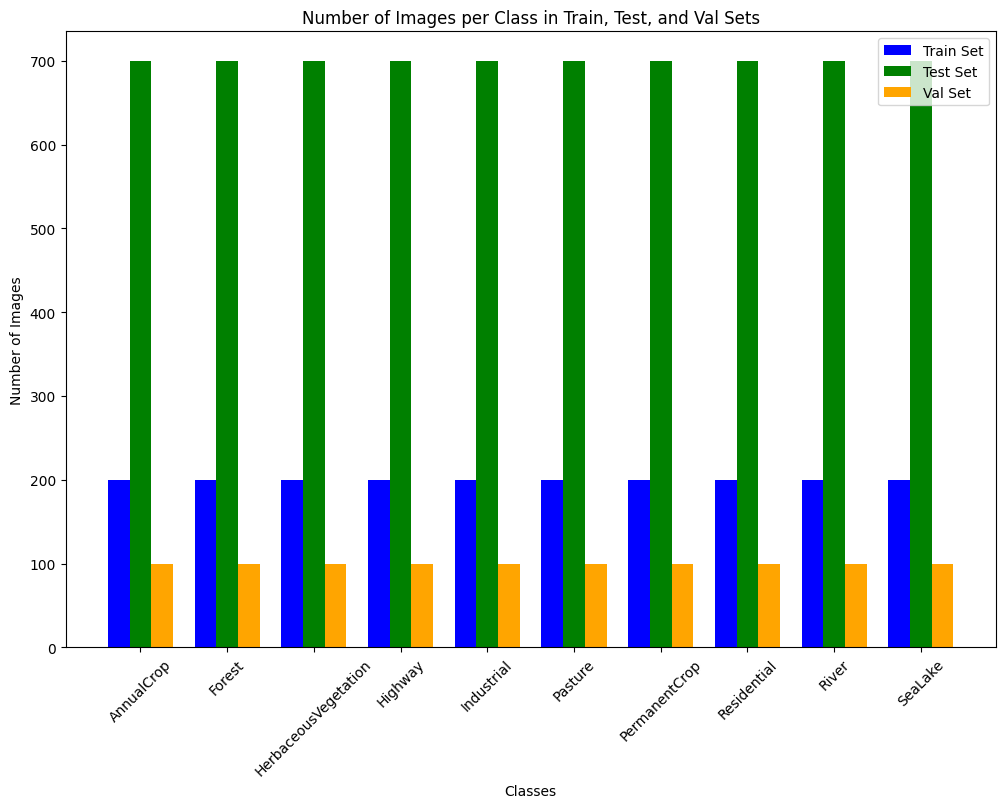

In [19]:
land_patches_train_dir_path = 'images/land_patches/train/'
land_patches_test_dir_path = 'images/land_patches/test/'
land_patches_val_dir_path = 'images/land_patches/val/'

class_names = []
for d in os.listdir(land_patches_train_dir_path):
  if os.path.isdir(os.path.join(land_patches_train_dir_path, d)):
    class_names.append(d)
class_names.sort()

number_classes = {}
for class_name in class_names:
    train_class_dir = os.path.join(land_patches_train_dir_path, class_name)
    test_class_dir = os.path.join(land_patches_test_dir_path, class_name)
    val_class_dir = os.path.join(land_patches_val_dir_path, class_name)

    train_count = len(os.listdir(train_class_dir))
    test_count = len(os.listdir(test_class_dir))
    val_count = len(os.listdir(val_class_dir))

    number_classes[class_name] = {'train_count': train_count, 'test_count': test_count, 'val_count': val_count}

labels = list(number_classes.keys())
train_vals = []
test_vals = []
val_vals = []
for v in number_classes.values():
    train_vals.append(v['train_count'])
    test_vals.append(v['test_count'])
    val_vals.append(v['val_count'])

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width, train_vals, width, label='Train Set', color='blue')
plt.bar(x, test_vals, width, label='Test Set', color='green')
plt.bar(x + width, val_vals, width, label='Val Set', color='orange')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train, Test, and Val Sets')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()

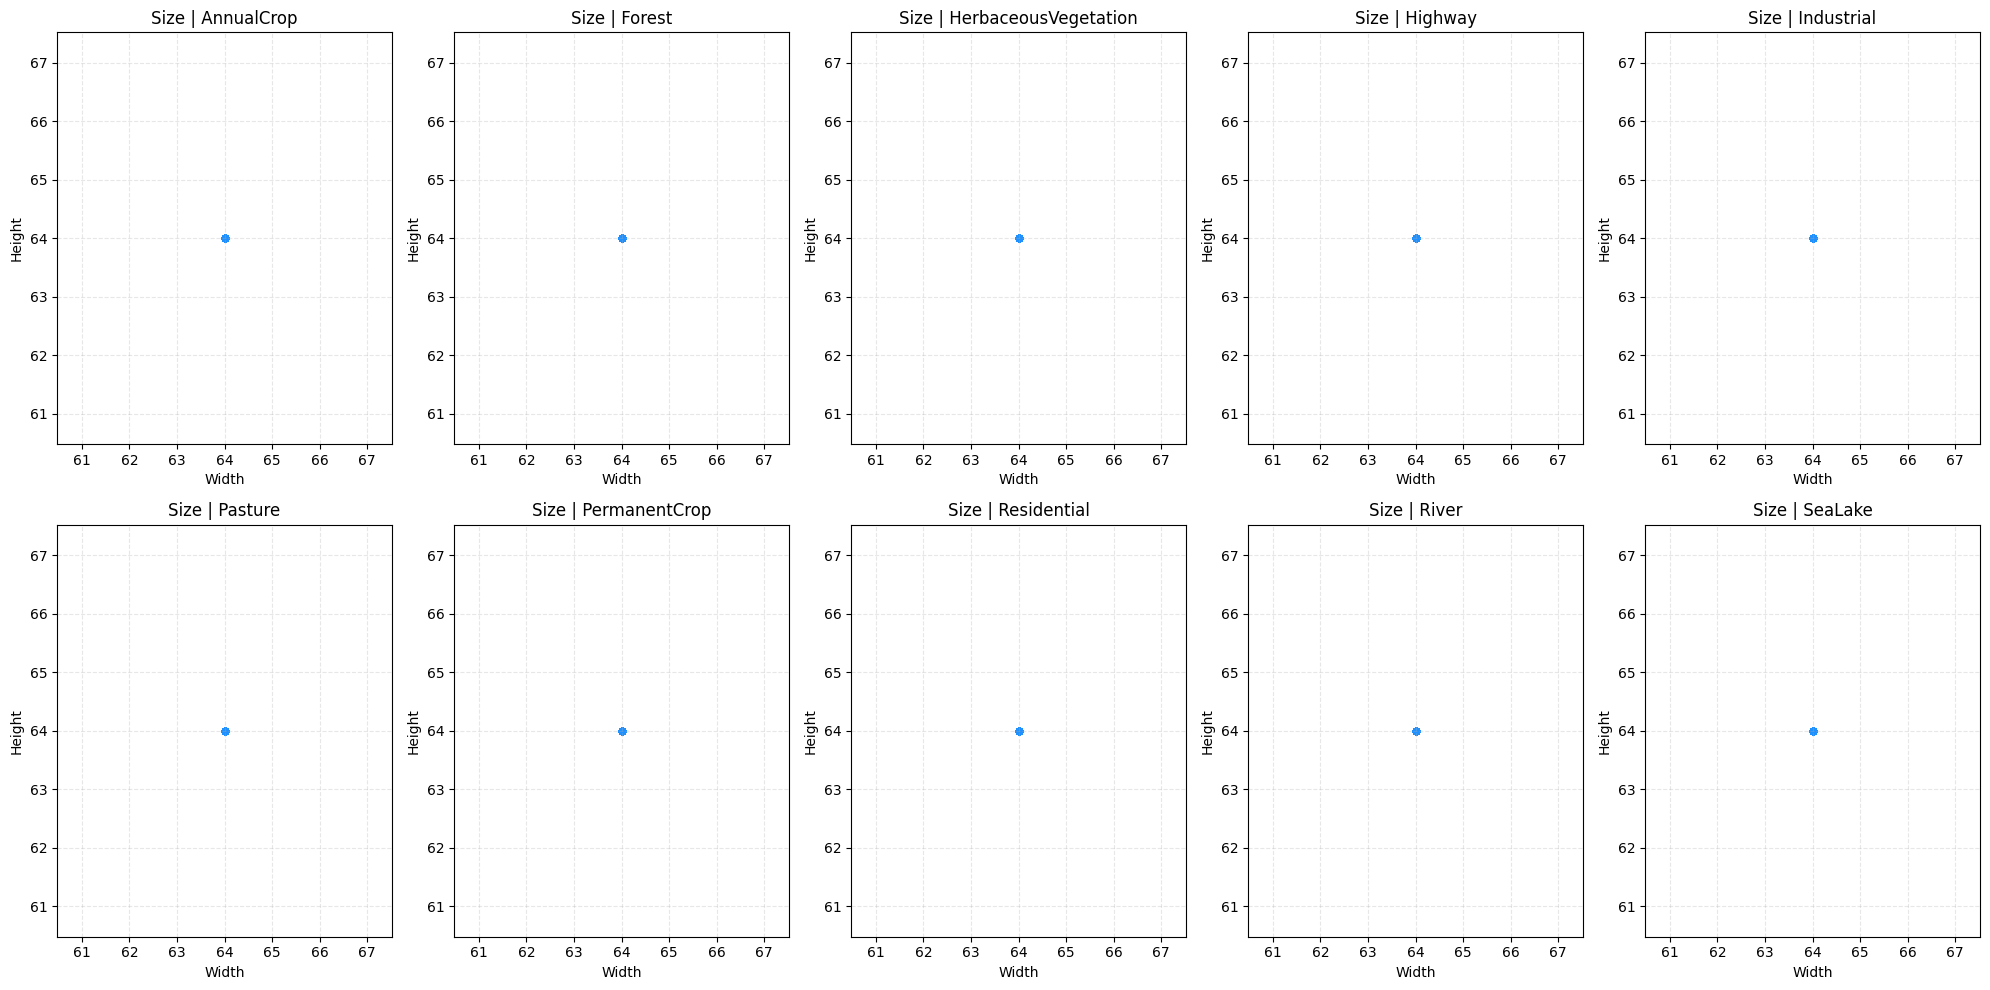

In [20]:
class_data = {}
for class_name in class_names:
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    images = os.listdir(class_dir)

    widths = []
    heights = []

    for img_name in images:
        if img_name.lower().endswith(('.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[class_name] = {'widths': widths, 'heights': heights}


fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):

    width = class_data[class_name]['widths']
    height = class_data[class_name]['heights']

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].scatter(width, height, alpha=0.5, s=20, color='dodgerblue')
    ax[row_idx, col_idx].set_title(f'Size | {class_name}')
    ax[row_idx, col_idx].set_xlabel('Width')
    ax[row_idx, col_idx].set_ylabel('Height')
    ax[row_idx, col_idx].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

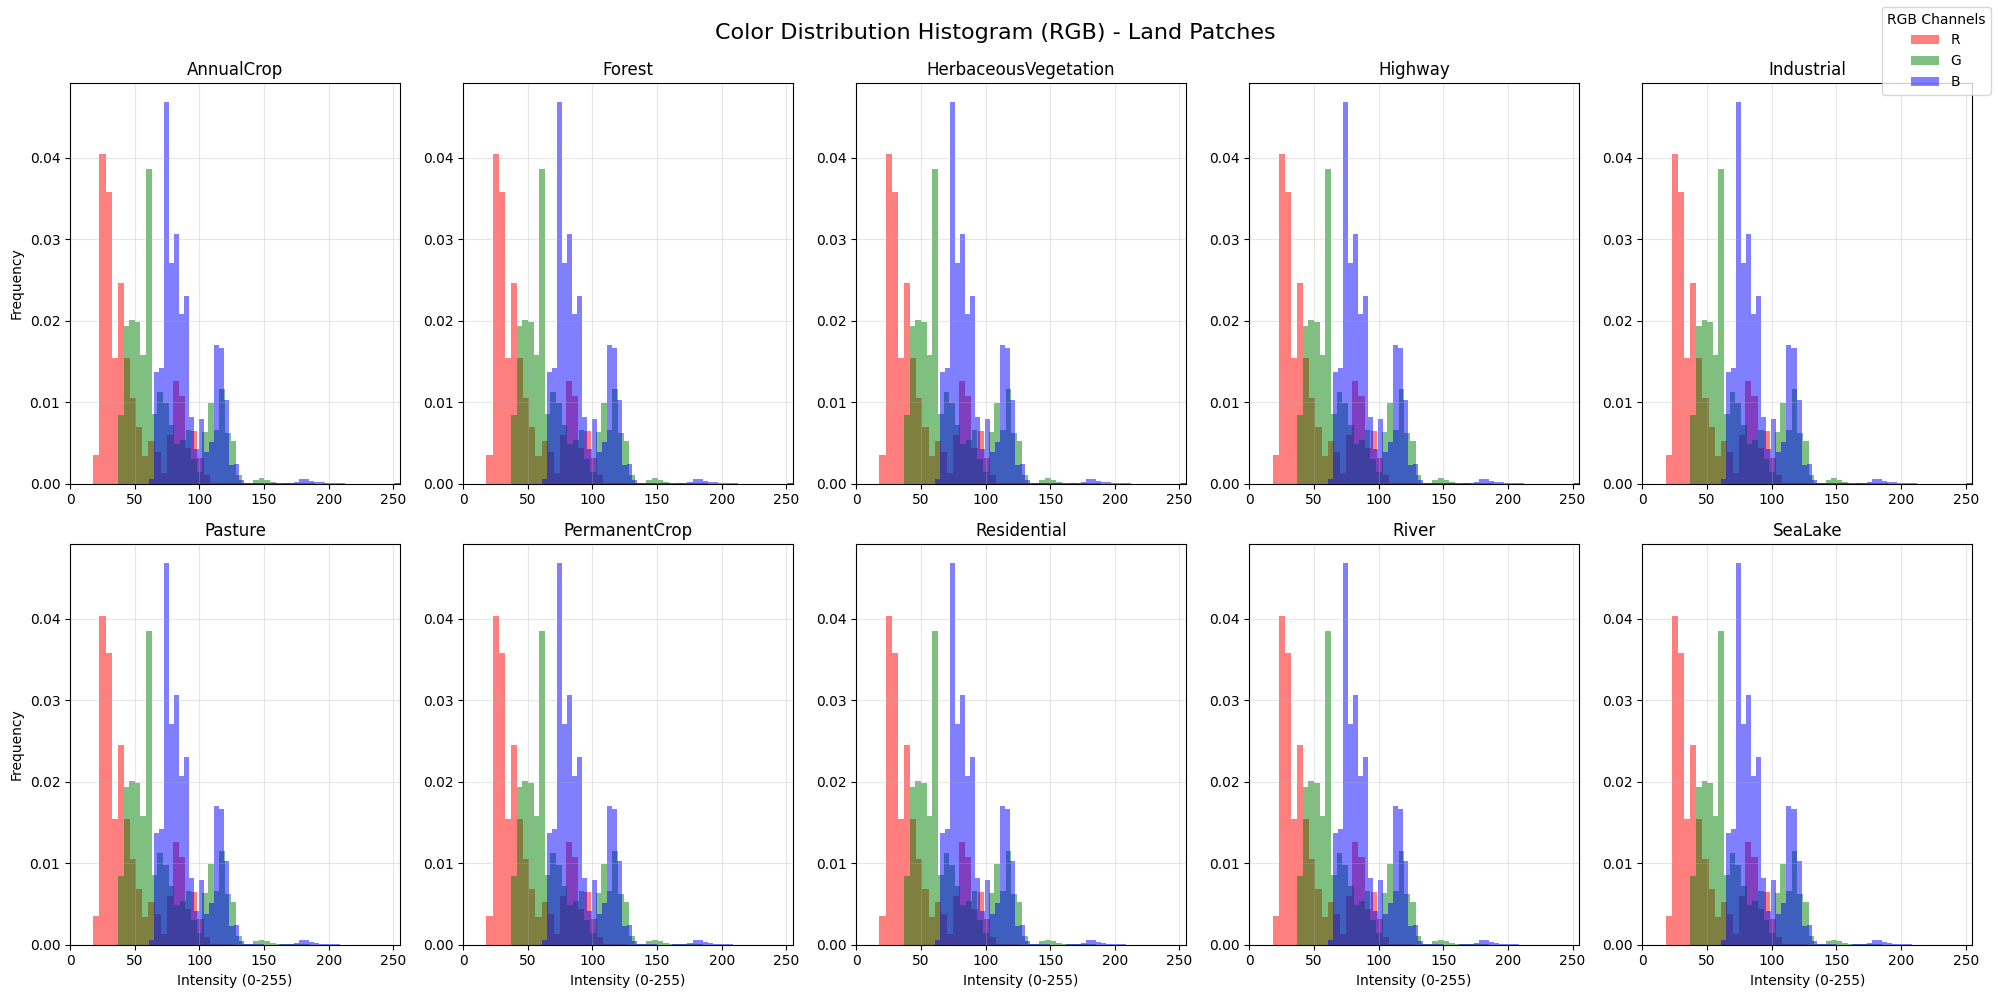

In [21]:
rgb_class = {}

for idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)

    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []

    for img_name in images:
        if img_name.lower().endswith(('.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())

    rgb_class[class_name] = { 'red': all_reds, 'green': all_greens, 'blue': all_blues }

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):
    red = rgb_class[class_name]["red"]
    green = rgb_class[class_name]["green"]
    blue = rgb_class[class_name]["blue"]

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].hist(all_reds, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax[row_idx, col_idx].hist(all_greens, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax[row_idx, col_idx].hist(all_blues, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax[row_idx, col_idx].set_title(f'{class_name}')
    ax[row_idx, col_idx].set_xlim(0, 255)

    if idx % 5 == 0:
        ax[row_idx, col_idx].set_ylabel('Frequency')
    if idx >= 5:
        ax[row_idx, col_idx].set_xlabel('Intensity (0-255)')

    ax[row_idx, col_idx].grid(True, alpha=0.3)

handles, labels = ax[row_idx, col_idx].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) - Land Patches", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

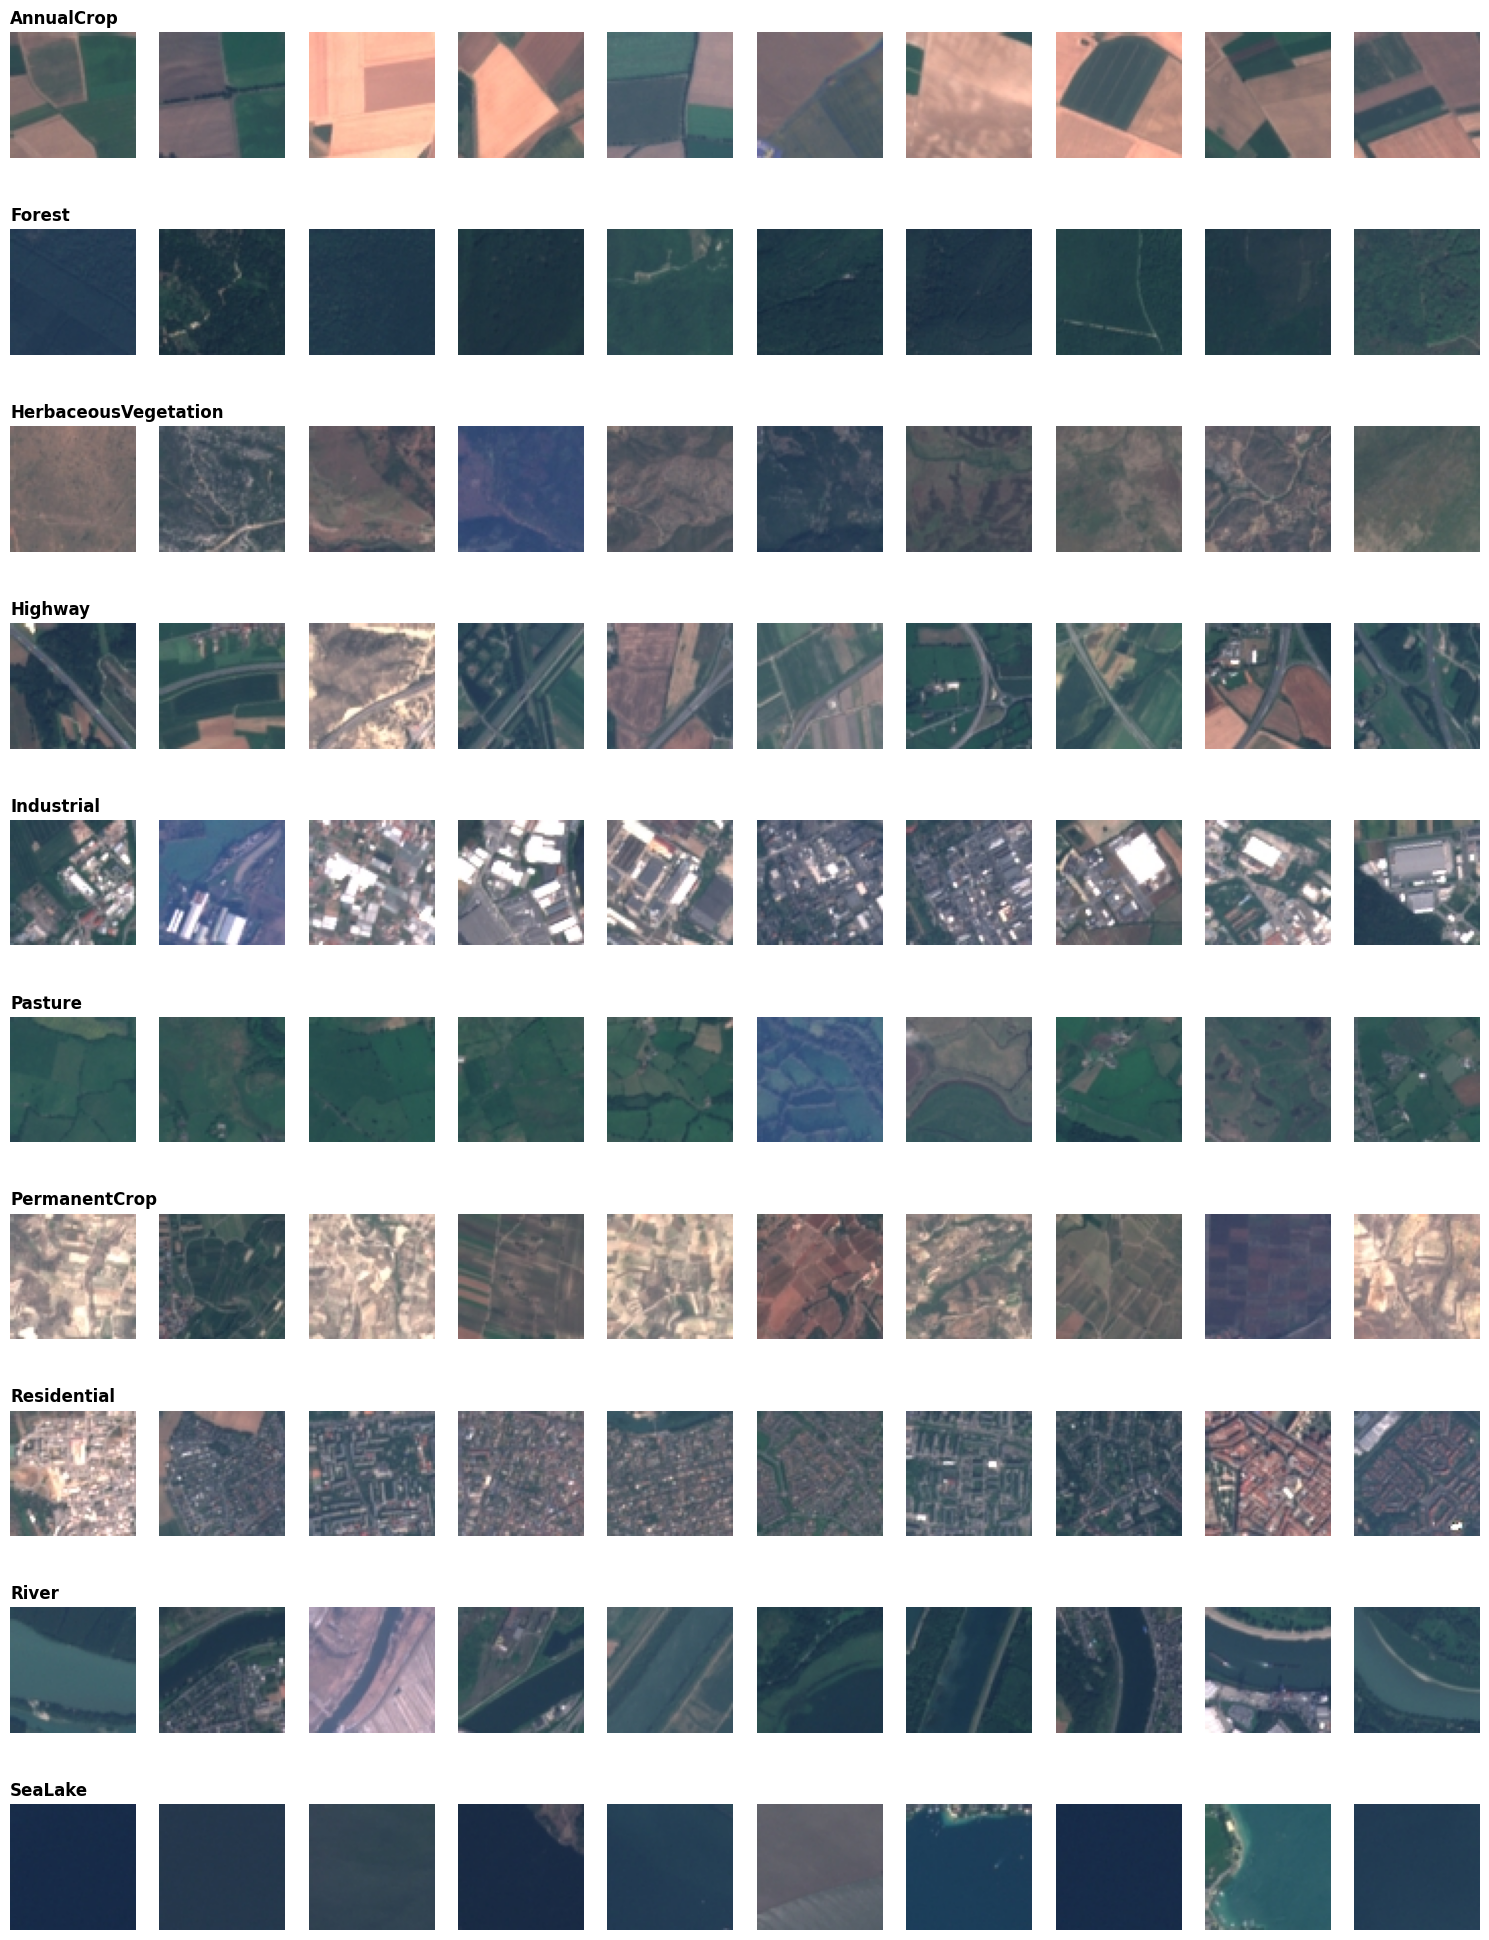

In [22]:
fig, ax = plt.subplots(nrows=len(class_names), ncols=10, figsize=(15, 20))

for row_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    all_imgs = []
    for f in os.listdir(class_dir):
        if f.lower().endswith(('.jpg')):
            all_imgs.append(f)

    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax[row_idx, col_idx].imshow(img)
            ax[row_idx, col_idx].axis('off')
            if col_idx == 0:
                ax[row_idx, col_idx].set_title(f'{class_name}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [23]:
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print(f"Running on device: {device}")

train_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_transform_land_aug = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

val_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images_land_aug = torchvision.datasets.ImageFolder(root=land_patches_train_dir_path, transform=train_transform_land_aug)
train_images_land = torchvision.datasets.ImageFolder(root=land_patches_train_dir_path, transform=train_transform_land)
val_images_land = torchvision.datasets.ImageFolder(root=land_patches_val_dir_path, transform=val_transform_land)
test_images_land = torchvision.datasets.ImageFolder(root=land_patches_test_dir_path, transform=test_transform_land)

print(f'Size of training labels {len(train_images_land.targets)}')
print(f'Size of augmented training labels {len(train_images_land_aug)}')
print(f'Size of test labels {len(test_images_land.targets)}')
print(f'Size of validation labels {len(val_images_land.targets)}')

Running on device: cuda
Size of training labels 2000
Size of augmented training labels 2000
Size of test labels 7000
Size of validation labels 1000


In [24]:
BATCH_SIZE_TRAIN = 64
BATCH_SIZE_TEST = 64
BATCH_SIZE_VALIDATION = 64
NO_WORKERS = 8
SHUFFLE_DATA = True

train_land_loader = torch.utils.data.DataLoader(train_images_land, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_land_images, batch_train_land_labels) = next(iter(train_land_loader))

print(f'Shape of training images: {batch_train_land_images.size()}')
print(f'Shape of training labels: {batch_train_land_labels.size()}')

train_land_loader_aug = torch.utils.data.DataLoader(train_images_land_aug, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_land_images_aug, batch_train_land_labels_aug) = next(iter(train_land_loader_aug))
print(f'Shape of augmented training images: {batch_train_land_images_aug.size()}')
print(f'Shape of augmented training labels: {batch_train_land_labels_aug.size()}')

val_land_loader = torch.utils.data.DataLoader(val_images_land, batch_size=BATCH_SIZE_VALIDATION, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_val_land_images, batch_val_land_labels) = next(iter(val_land_loader))
print(f'Shape of validation images: {batch_val_land_images.size()}')
print(f'Shape of validation labels: {batch_val_land_labels.size()}')

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


Shape of training images: torch.Size([64, 3, 64, 64])
Shape of training labels: torch.Size([64])
Shape of augmented training images: torch.Size([64, 3, 64, 64])
Shape of augmented training labels: torch.Size([64])
Shape of validation images: torch.Size([64, 3, 64, 64])
Shape of validation labels: torch.Size([64])


In [25]:
test_land_loader = torch.utils.data.DataLoader(test_images_land, batch_size=BATCH_SIZE_TEST, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_land_images, batch_test_land_labels) = next(iter(test_land_loader))
print(f'Shape of test images: {batch_test_land_images.size()}')
print(f'Shape of test labels: {batch_test_land_labels.size()}')

Shape of test images: torch.Size([64, 3, 64, 64])
Shape of test labels: torch.Size([64])


In [26]:
def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.plot(steps, loss_list, c='b')
    time.sleep(1.0)

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k

In [27]:
def train_engine_land(net, train_data_loader, val_data_loader, optimizer, scheduler, num_epochs=35, name="Experiment"):

    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    val_data_provider = loopy_test_loader(val_data_loader)

    net.train()

    for epoch in range(num_epochs):
        for i, data in enumerate(train_data_loader, 0):

            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_acc += top_k_accuracy(1, labels, outputs).item()

            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            if train_iter % REPORT_TEST_EVERY == 0:
                net.eval()
                with torch.no_grad():
                    val_iter = 0
                    val_loss_accum = 0.0
                    val_acc_accum = 0.0

                    while val_iter < TEST_ITERS:
                        try:
                            val_data = next(val_data_provider)
                        except StopIteration:
                            val_data_provider = loopy_test_loader(val_data_loader)
                            val_data = next(val_data_provider)

                        v_in, v_lbl = val_data[0].to(device), val_data[1].to(device)
                        v_out = net(v_in)

                        val_loss_accum += criterion(v_out, v_lbl).item()
                        val_acc_accum += top_k_accuracy(1, v_lbl, v_out).item()
                        val_iter += 1

                    avg_val_loss = val_loss_accum / TEST_ITERS
                    avg_val_acc = val_acc_accum / TEST_ITERS

                    if name == "Validation":
                        print(f'>>> [{name} VALIDATION] Loss: {avg_val_loss:.5f}, Acc: {avg_val_acc:.2f}%')
                    else:
                      print(f'>>> [{name} Test] Loss: {avg_val_loss:.5f}, Acc: {avg_val_acc:.2f}%')


                    history['val_loss'].append(avg_val_loss)
                    history['val_acc'].append(avg_val_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        scheduler.step()

    print(f"Finished: {name}")
    return history

In [28]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 64, hidden_size=512, out_size=256, num_classes=10, dropout_val=0.5):
        super(MLP, self).__init__()

        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, out_size)
        self.fc3 = nn.Linear(out_size, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [29]:
import torch
import torch.nn as nn

class LeNet(nn.Module):
    def __init__(self, img_size=64, num_classes=10, in_size=512, hidden_size1=1024, hidden_size2=1024, use_batch_norm=False, dropout_val=0.5):
        super(LeNet, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
        if use_batch_norm:
            self.bn1 = nn.BatchNorm2d(6)
        else:
            self.bn1 = nn.Identity()

        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        if use_batch_norm:
            self.bn2 = nn.BatchNorm2d(16)
        else:
            self.bn2 = nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.size = img_size - 5 + 1
        self.size = self.size // 2
        self.size = self.size - 5 + 1
        self.size = self.size // 2

        flatten_size = 16 * self.size * self.size

        self.fc1 = nn.Linear(in_features=flatten_size, out_features=hidden_size1)
        self.fc2 = nn.Linear(in_features=hidden_size1, out_features=hidden_size2)
        self.fc3 = nn.Linear(in_features=hidden_size2, out_features=num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.pool(x)

        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x


Starting: MLP_Safe_SGD


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


>>> [MLP_Safe_SGD Test] Loss: 2.28922, Acc: 14.68%
[MLP_Safe_SGD] [Ep: 4, Step: 99] Train Loss: 2.04925, Acc: 22.02%
[MLP_Safe_SGD] [Ep: 7, Step: 199] Train Loss: 1.77286, Acc: 30.84%
>>> [MLP_Safe_SGD Test] Loss: 1.71585, Acc: 38.33%
[MLP_Safe_SGD] [Ep: 10, Step: 299] Train Loss: 1.67993, Acc: 35.89%
[MLP_Safe_SGD] [Ep: 13, Step: 399] Train Loss: 1.57528, Acc: 40.94%
>>> [MLP_Safe_SGD Test] Loss: 1.52126, Acc: 48.70%
[MLP_Safe_SGD] [Ep: 16, Step: 499] Train Loss: 1.50067, Acc: 44.23%
[MLP_Safe_SGD] [Ep: 19, Step: 599] Train Loss: 1.33742, Acc: 52.11%
>>> [MLP_Safe_SGD Test] Loss: 1.42589, Acc: 51.36%
Finished: MLP_Safe_SGD


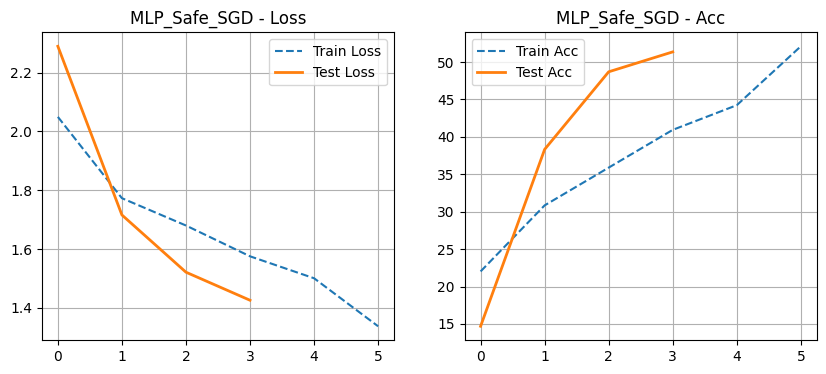


Starting: MLP_Small_Adam
>>> [MLP_Small_Adam Test] Loss: 2.45600, Acc: 14.33%
[MLP_Small_Adam] [Ep: 4, Step: 99] Train Loss: 2.07577, Acc: 24.97%
[MLP_Small_Adam] [Ep: 7, Step: 199] Train Loss: 1.75735, Acc: 33.41%
>>> [MLP_Small_Adam Test] Loss: 1.68478, Acc: 42.22%
[MLP_Small_Adam] [Ep: 10, Step: 299] Train Loss: 1.60806, Acc: 38.88%
[MLP_Small_Adam] [Ep: 13, Step: 399] Train Loss: 1.52242, Acc: 43.14%
>>> [MLP_Small_Adam Test] Loss: 1.51362, Acc: 48.87%
[MLP_Small_Adam] [Ep: 16, Step: 499] Train Loss: 1.43125, Acc: 47.36%
[MLP_Small_Adam] [Ep: 19, Step: 599] Train Loss: 1.26069, Acc: 54.75%
>>> [MLP_Small_Adam Test] Loss: 1.40111, Acc: 53.79%
Finished: MLP_Small_Adam


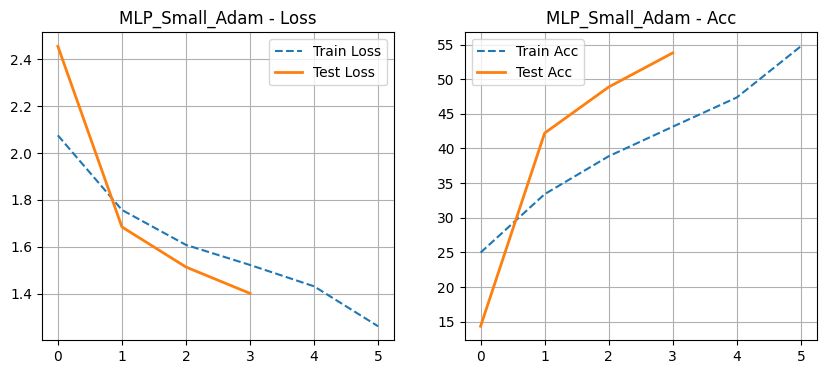


Starting: MLP_Large_HighReg
>>> [MLP_Large_HighReg Test] Loss: 2.89572, Acc: 15.54%
[MLP_Large_HighReg] [Ep: 4, Step: 99] Train Loss: 2.24552, Acc: 21.67%
[MLP_Large_HighReg] [Ep: 7, Step: 199] Train Loss: 1.85984, Acc: 27.97%
>>> [MLP_Large_HighReg Test] Loss: 1.76862, Acc: 32.87%
[MLP_Large_HighReg] [Ep: 10, Step: 299] Train Loss: 1.75897, Acc: 32.27%
[MLP_Large_HighReg] [Ep: 13, Step: 399] Train Loss: 1.67872, Acc: 35.20%
>>> [MLP_Large_HighReg Test] Loss: 1.73936, Acc: 36.65%
[MLP_Large_HighReg] [Ep: 16, Step: 499] Train Loss: 1.62882, Acc: 38.16%
[MLP_Large_HighReg] [Ep: 19, Step: 599] Train Loss: 1.42658, Acc: 46.80%
>>> [MLP_Large_HighReg Test] Loss: 1.55967, Acc: 47.40%
Finished: MLP_Large_HighReg


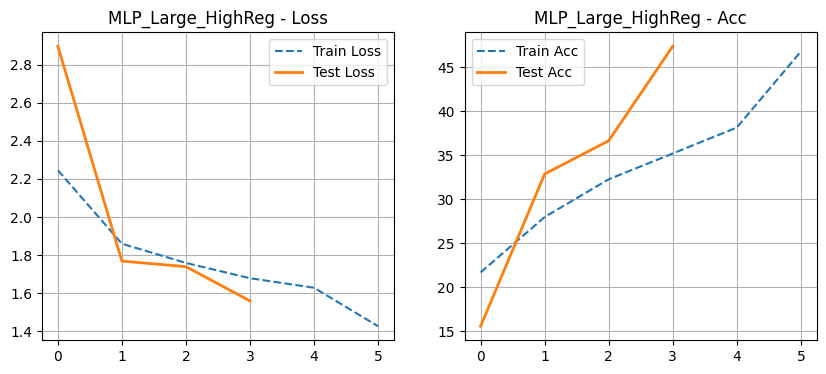


Starting: MLP_Power_Adam
>>> [MLP_Power_Adam Test] Loss: 2.69092, Acc: 16.09%
[MLP_Power_Adam] [Ep: 4, Step: 99] Train Loss: 2.15387, Acc: 22.42%
[MLP_Power_Adam] [Ep: 7, Step: 199] Train Loss: 1.85518, Acc: 29.02%
>>> [MLP_Power_Adam Test] Loss: 2.05123, Acc: 22.60%
[MLP_Power_Adam] [Ep: 10, Step: 299] Train Loss: 1.77098, Acc: 31.41%
[MLP_Power_Adam] [Ep: 13, Step: 399] Train Loss: 1.70189, Acc: 34.75%
>>> [MLP_Power_Adam Test] Loss: 2.40567, Acc: 22.08%
[MLP_Power_Adam] [Ep: 16, Step: 499] Train Loss: 1.70473, Acc: 36.23%
[MLP_Power_Adam] [Ep: 19, Step: 599] Train Loss: 1.57924, Acc: 41.38%
>>> [MLP_Power_Adam Test] Loss: 2.52606, Acc: 24.54%
[MLP_Power_Adam] [Ep: 22, Step: 699] Train Loss: 1.54213, Acc: 43.95%
[MLP_Power_Adam] [Ep: 25, Step: 799] Train Loss: 1.50213, Acc: 44.23%
>>> [MLP_Power_Adam Test] Loss: 2.59477, Acc: 24.56%
[MLP_Power_Adam] [Ep: 29, Step: 899] Train Loss: 1.51002, Acc: 44.45%
[MLP_Power_Adam] [Ep: 32, Step: 999] Train Loss: 1.50055, Acc: 44.91%
>>> [MLP_Pow

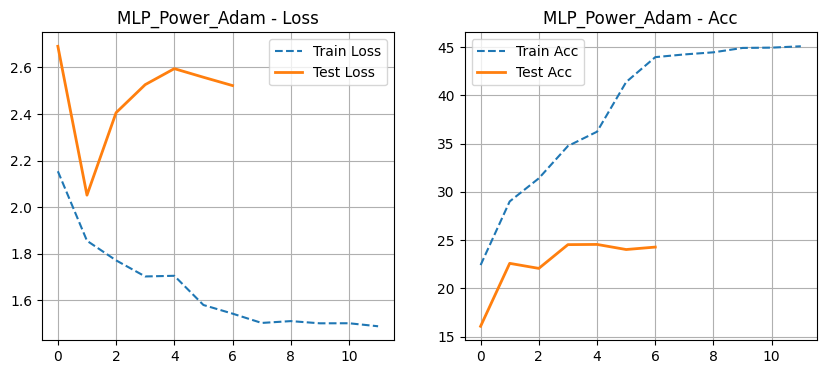


Starting: MLP_Wide_SGD
>>> [MLP_Wide_SGD Test] Loss: 2.29971, Acc: 12.29%
[MLP_Wide_SGD] [Ep: 4, Step: 99] Train Loss: 2.01791, Acc: 22.05%
[MLP_Wide_SGD] [Ep: 7, Step: 199] Train Loss: 1.82960, Acc: 27.75%
>>> [MLP_Wide_SGD Test] Loss: 2.34764, Acc: 22.07%
[MLP_Wide_SGD] [Ep: 10, Step: 299] Train Loss: 1.79526, Acc: 29.84%
[MLP_Wide_SGD] [Ep: 13, Step: 399] Train Loss: 1.76579, Acc: 32.00%
>>> [MLP_Wide_SGD Test] Loss: 2.32537, Acc: 22.90%
[MLP_Wide_SGD] [Ep: 16, Step: 499] Train Loss: 1.72072, Acc: 34.61%
[MLP_Wide_SGD] [Ep: 19, Step: 599] Train Loss: 1.61161, Acc: 39.98%
>>> [MLP_Wide_SGD Test] Loss: 2.58080, Acc: 23.72%
[MLP_Wide_SGD] [Ep: 22, Step: 699] Train Loss: 1.60099, Acc: 40.25%
[MLP_Wide_SGD] [Ep: 25, Step: 799] Train Loss: 1.58398, Acc: 40.50%
>>> [MLP_Wide_SGD Test] Loss: 2.70771, Acc: 24.66%
[MLP_Wide_SGD] [Ep: 29, Step: 899] Train Loss: 1.55527, Acc: 42.11%
[MLP_Wide_SGD] [Ep: 32, Step: 999] Train Loss: 1.56016, Acc: 41.81%
>>> [MLP_Wide_SGD Test] Loss: 2.70644, Acc: 

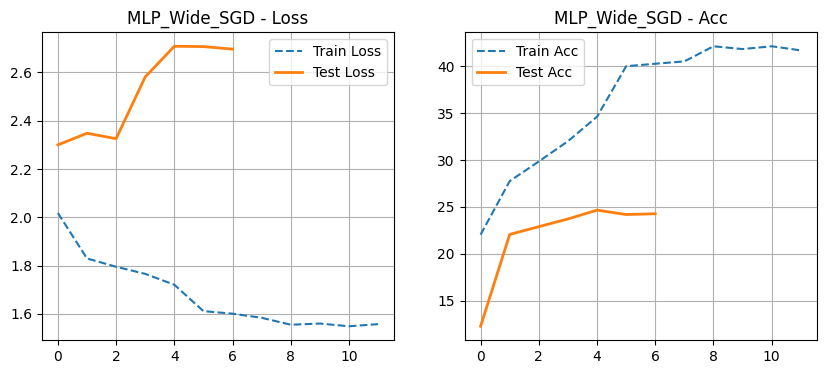


Starting: MLP_Balanced_Adam
>>> [MLP_Balanced_Adam Test] Loss: 2.34947, Acc: 15.40%
[MLP_Balanced_Adam] [Ep: 4, Step: 99] Train Loss: 2.06609, Acc: 24.08%
[MLP_Balanced_Adam] [Ep: 7, Step: 199] Train Loss: 1.83688, Acc: 29.50%
>>> [MLP_Balanced_Adam Test] Loss: 2.21605, Acc: 23.68%
[MLP_Balanced_Adam] [Ep: 10, Step: 299] Train Loss: 1.74848, Acc: 33.78%
[MLP_Balanced_Adam] [Ep: 13, Step: 399] Train Loss: 1.70009, Acc: 36.11%
>>> [MLP_Balanced_Adam Test] Loss: 2.68828, Acc: 23.85%
[MLP_Balanced_Adam] [Ep: 16, Step: 499] Train Loss: 1.63994, Acc: 38.84%
[MLP_Balanced_Adam] [Ep: 19, Step: 599] Train Loss: 1.57689, Acc: 41.88%
>>> [MLP_Balanced_Adam Test] Loss: 2.51758, Acc: 26.19%
[MLP_Balanced_Adam] [Ep: 22, Step: 699] Train Loss: 1.54331, Acc: 42.97%
[MLP_Balanced_Adam] [Ep: 25, Step: 799] Train Loss: 1.53521, Acc: 43.67%
>>> [MLP_Balanced_Adam Test] Loss: 2.48039, Acc: 26.38%
[MLP_Balanced_Adam] [Ep: 29, Step: 899] Train Loss: 1.52526, Acc: 44.31%
[MLP_Balanced_Adam] [Ep: 32, Step: 99

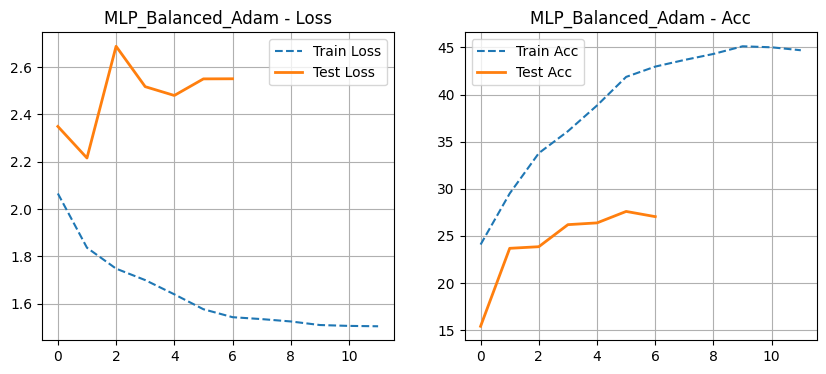


Top Results by Accuracy:
               Model  Hidden Size  Dropout  Augmentation Optimizator     LR  \
1     MLP_Small_Adam          256      0.4         False        adam  0.001   
0       MLP_Safe_SGD          512      0.5         False         sgd  0.010   
2  MLP_Large_HighReg         1024      0.5         False        adam  0.001   
5  MLP_Balanced_Adam          512      0.3          True        adam  0.001   
3     MLP_Power_Adam         1024      0.3          True        adam  0.001   
4       MLP_Wide_SGD         1024      0.4          True         sgd  0.010   

  Final Val Acc Final Val Loss  
1        53.79%         1.4011  
0        51.36%         1.4259  
2        47.40%         1.5597  
5        27.04%         2.5509  
3        24.29%         2.5221  
4        24.27%         2.6959  


In [31]:
experiments = [
    {
        "name": "MLP_Safe_SGD",
        "hidden_size": 512,
        "dropout_val": 0.5,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": False
    },
    {
        "name": "MLP_Small_Adam",
        "hidden_size": 256,
        "dropout_val": 0.4,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "MLP_Large_HighReg",
        "hidden_size": 1024,
        "dropout_val": 0.5,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "MLP_Power_Adam",
        "hidden_size": 1024,
        "dropout_val": 0.3,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": True
    },
    {
        "name": "MLP_Wide_SGD",
        "hidden_size": 1024,
        "dropout_val": 0.4,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": True
    },
    {
        "name": "MLP_Balanced_Adam",
        "hidden_size": 512,
        "dropout_val": 0.3,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": True
    }
]

best_acc = 0.0
best_model_name = None
best_config = {}
all_results = []

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = MLP(img_size=64, hidden_size=exp['hidden_size'], dropout_val=exp['dropout_val']).to(device)

    if exp['augmentation']:
        current_train_loader = train_land_loader_aug
        num_epochs = 40
    else:
        current_train_loader = train_land_loader
        num_epochs = 20

    if exp['optimizer'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=1e-4)

    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

    hist = train_engine_land(net=net, train_data_loader=current_train_loader, val_data_loader=val_land_loader,
                             optimizer=optimizer, scheduler=scheduler, num_epochs=num_epochs, name=exp['name'])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Test Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Test Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()
    if torch.is_tensor(final_loss):
        final_loss = final_loss.item()

    all_results.append({
        "Model": exp['name'],
        "Hidden Size": exp['hidden_size'],
        "Dropout": exp['dropout_val'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['optimizer'],
        "LR": exp['lr'],
        "Final Val Acc": final_acc,
        "Final Val Loss": final_loss
    })

    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config = exp.copy()

if all_results:
    df_results = pd.DataFrame(all_results)

    df_display = df_results.copy()
    df_display['Final Val Acc'] = df_display['Final Val Acc'].apply(lambda x: f"{x:.2f}%")
    df_display['Final Val Loss'] = df_display['Final Val Loss'].apply(lambda x: f"{x:.4f}")

    print("\nTop Results by Accuracy:")
    print(df_display.sort_values(by='Final Val Acc', ascending=False).head(6))

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


>>> [Test Test] Loss: 2.46373, Acc: 18.35%
[Test] [Ep: 4, Step: 99] Train Loss: 2.12268, Acc: 23.70%
[Test] [Ep: 7, Step: 199] Train Loss: 1.76059, Acc: 32.91%
>>> [Test Test] Loss: 1.66092, Acc: 41.19%
[Test] [Ep: 10, Step: 299] Train Loss: 1.59799, Acc: 39.09%
[Test] [Ep: 13, Step: 399] Train Loss: 1.53424, Acc: 43.23%
>>> [Test Test] Loss: 1.56814, Acc: 47.15%
[Test] [Ep: 16, Step: 499] Train Loss: 1.42562, Acc: 47.56%
[Test] [Ep: 19, Step: 599] Train Loss: 1.25396, Acc: 54.81%
>>> [Test Test] Loss: 1.42265, Acc: 53.29%
Finished: Test


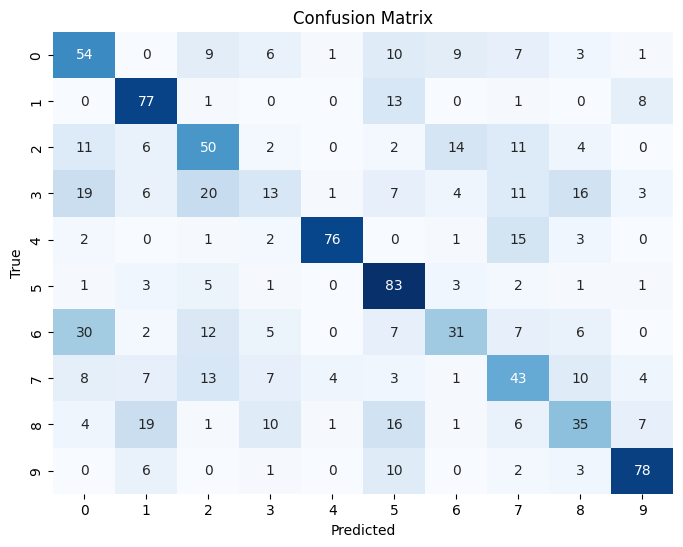

In [33]:
p = best_config

if p['augmentation']:
    final_train_loader = train_land_loader_aug
    final_epochs = 40
else:
    final_train_loader = train_land_loader
    final_epochs = 20

net = MLP(img_size=64, hidden_size=p['hidden_size'], dropout_val=p['dropout_val']).to(device)

if p['optimizer'] == 'sgd':
    optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)
else:
    optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

hist = train_engine_land(net=net, train_data_loader=final_train_loader, val_data_loader=val_land_loader,
                         optimizer=optimizer, scheduler=scheduler, num_epochs=final_epochs, name="Test")

all_preds = []
all_labels = []

net.eval()
with torch.no_grad():
    for images, labels in val_land_loader:
        images = images.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Starting: LeNet_Base_Adam_NoAug


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


>>> [Validation VALIDATION] Loss: 2.29780, Acc: 10.17%
[Validation] [Ep: 4, Step: 99] Train Loss: 1.80125, Acc: 32.00%
[Validation] [Ep: 7, Step: 199] Train Loss: 1.42614, Acc: 46.59%
>>> [Validation VALIDATION] Loss: 1.50140, Acc: 47.78%
[Validation] [Ep: 10, Step: 299] Train Loss: 1.26490, Acc: 51.59%
[Validation] [Ep: 13, Step: 399] Train Loss: 1.16302, Acc: 57.06%
>>> [Validation VALIDATION] Loss: 1.26986, Acc: 58.45%
[Validation] [Ep: 16, Step: 499] Train Loss: 1.06001, Acc: 61.05%
[Validation] [Ep: 19, Step: 599] Train Loss: 0.94135, Acc: 66.02%
>>> [Validation VALIDATION] Loss: 0.91820, Acc: 70.24%
Finished: Validation


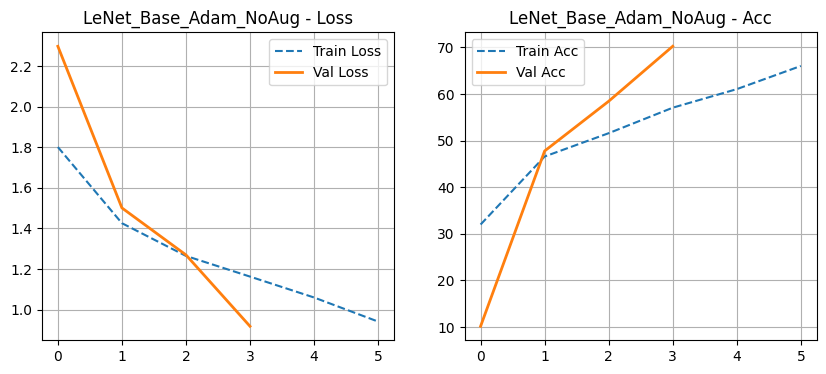


Starting: LeNet_SGD_Classic_NoAug
>>> [Validation VALIDATION] Loss: 2.30383, Acc: 9.89%
[Validation] [Ep: 4, Step: 99] Train Loss: 1.87351, Acc: 28.22%
[Validation] [Ep: 7, Step: 199] Train Loss: 1.45428, Acc: 44.33%
>>> [Validation VALIDATION] Loss: 1.26359, Acc: 52.57%
[Validation] [Ep: 10, Step: 299] Train Loss: 1.23675, Acc: 54.42%
[Validation] [Ep: 13, Step: 399] Train Loss: 1.17104, Acc: 57.25%
>>> [Validation VALIDATION] Loss: 1.09101, Acc: 62.63%
[Validation] [Ep: 16, Step: 499] Train Loss: 0.97013, Acc: 64.80%
[Validation] [Ep: 19, Step: 599] Train Loss: 0.79997, Acc: 71.02%
>>> [Validation VALIDATION] Loss: 0.85024, Acc: 69.58%
Finished: Validation


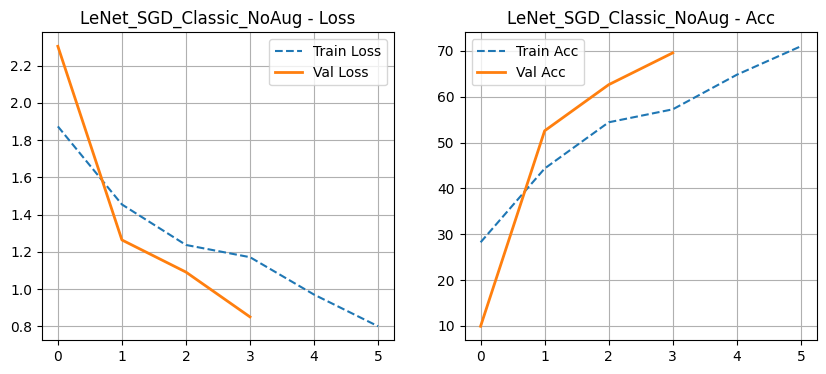


Starting: LeNet_Small_Reg_NoAug
>>> [Validation VALIDATION] Loss: 2.30590, Acc: 9.93%
[Validation] [Ep: 4, Step: 99] Train Loss: 2.08125, Acc: 21.89%
[Validation] [Ep: 7, Step: 199] Train Loss: 1.73376, Acc: 33.53%
>>> [Validation VALIDATION] Loss: 1.47377, Acc: 43.42%
[Validation] [Ep: 10, Step: 299] Train Loss: 1.53581, Acc: 38.45%
[Validation] [Ep: 13, Step: 399] Train Loss: 1.40704, Acc: 43.72%
>>> [Validation VALIDATION] Loss: 1.37436, Acc: 48.11%
[Validation] [Ep: 16, Step: 499] Train Loss: 1.33578, Acc: 46.59%
[Validation] [Ep: 19, Step: 599] Train Loss: 1.24390, Acc: 50.11%
>>> [Validation VALIDATION] Loss: 1.26950, Acc: 52.98%
Finished: Validation


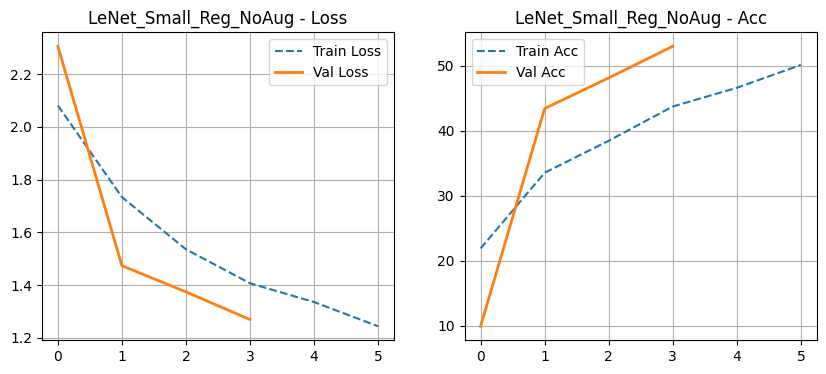


Starting: LeNet_Big_Adam_Aug
>>> [Validation VALIDATION] Loss: 2.29276, Acc: 18.82%
[Validation] [Ep: 4, Step: 99] Train Loss: 1.62018, Acc: 37.56%
[Validation] [Ep: 7, Step: 199] Train Loss: 1.32490, Acc: 49.98%
>>> [Validation VALIDATION] Loss: 1.26201, Acc: 52.68%
[Validation] [Ep: 10, Step: 299] Train Loss: 1.19326, Acc: 55.38%
[Validation] [Ep: 13, Step: 399] Train Loss: 1.15234, Acc: 57.42%
>>> [Validation VALIDATION] Loss: 0.94693, Acc: 63.64%
[Validation] [Ep: 16, Step: 499] Train Loss: 1.06728, Acc: 60.80%
[Validation] [Ep: 19, Step: 599] Train Loss: 0.93379, Acc: 66.05%
>>> [Validation VALIDATION] Loss: 0.78945, Acc: 72.79%
[Validation] [Ep: 22, Step: 699] Train Loss: 0.92576, Acc: 66.39%
[Validation] [Ep: 25, Step: 799] Train Loss: 0.90631, Acc: 67.14%
>>> [Validation VALIDATION] Loss: 0.76555, Acc: 72.50%
[Validation] [Ep: 29, Step: 899] Train Loss: 0.90022, Acc: 67.09%
[Validation] [Ep: 32, Step: 999] Train Loss: 0.89408, Acc: 67.83%
>>> [Validation VALIDATION] Loss: 0.73

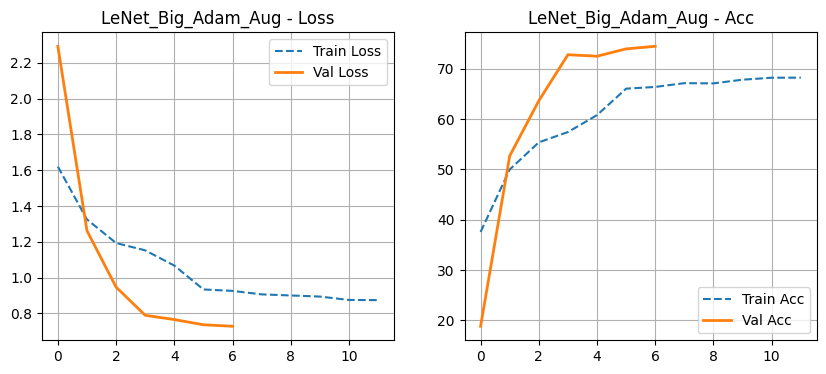


Starting: LeNet_Wide_SGD_Aug
>>> [Validation VALIDATION] Loss: 2.30260, Acc: 7.21%
[Validation] [Ep: 4, Step: 99] Train Loss: 1.85146, Acc: 28.45%
[Validation] [Ep: 7, Step: 199] Train Loss: 1.54058, Acc: 40.33%
>>> [Validation VALIDATION] Loss: 1.47553, Acc: 43.35%
[Validation] [Ep: 10, Step: 299] Train Loss: 1.41578, Acc: 44.97%
[Validation] [Ep: 13, Step: 399] Train Loss: 1.29348, Acc: 51.23%
>>> [Validation VALIDATION] Loss: 1.40793, Acc: 50.59%
[Validation] [Ep: 16, Step: 499] Train Loss: 1.20443, Acc: 54.59%
[Validation] [Ep: 19, Step: 599] Train Loss: 1.07422, Acc: 60.11%
>>> [Validation VALIDATION] Loss: 0.93725, Acc: 67.71%
[Validation] [Ep: 22, Step: 699] Train Loss: 1.04442, Acc: 61.34%
[Validation] [Ep: 25, Step: 799] Train Loss: 1.04439, Acc: 61.23%
>>> [Validation VALIDATION] Loss: 0.89972, Acc: 69.13%
[Validation] [Ep: 29, Step: 899] Train Loss: 0.99097, Acc: 63.31%
[Validation] [Ep: 32, Step: 999] Train Loss: 1.00875, Acc: 63.50%
>>> [Validation VALIDATION] Loss: 0.874

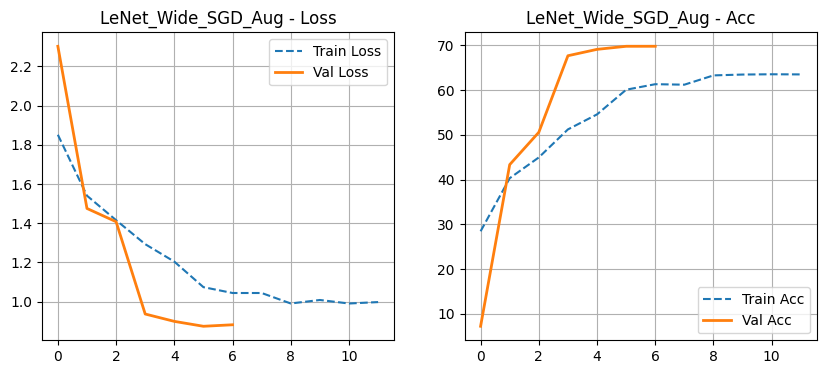


Starting: LeNet_Balanced_Aug
>>> [Validation VALIDATION] Loss: 2.30411, Acc: 10.00%
[Validation] [Ep: 4, Step: 99] Train Loss: 1.59877, Acc: 38.73%
[Validation] [Ep: 7, Step: 199] Train Loss: 1.27848, Acc: 51.59%
>>> [Validation VALIDATION] Loss: 1.01990, Acc: 63.97%
[Validation] [Ep: 10, Step: 299] Train Loss: 1.23182, Acc: 54.75%
[Validation] [Ep: 13, Step: 399] Train Loss: 1.10633, Acc: 58.81%
>>> [Validation VALIDATION] Loss: 0.91997, Acc: 67.88%
[Validation] [Ep: 16, Step: 499] Train Loss: 1.06637, Acc: 60.69%
[Validation] [Ep: 19, Step: 599] Train Loss: 0.94871, Acc: 66.17%
>>> [Validation VALIDATION] Loss: 0.81074, Acc: 71.57%
[Validation] [Ep: 22, Step: 699] Train Loss: 0.95098, Acc: 64.73%
[Validation] [Ep: 25, Step: 799] Train Loss: 0.93123, Acc: 66.08%
>>> [Validation VALIDATION] Loss: 0.78565, Acc: 73.02%
[Validation] [Ep: 29, Step: 899] Train Loss: 0.89354, Acc: 67.52%
[Validation] [Ep: 32, Step: 999] Train Loss: 0.91679, Acc: 66.52%
>>> [Validation VALIDATION] Loss: 0.77

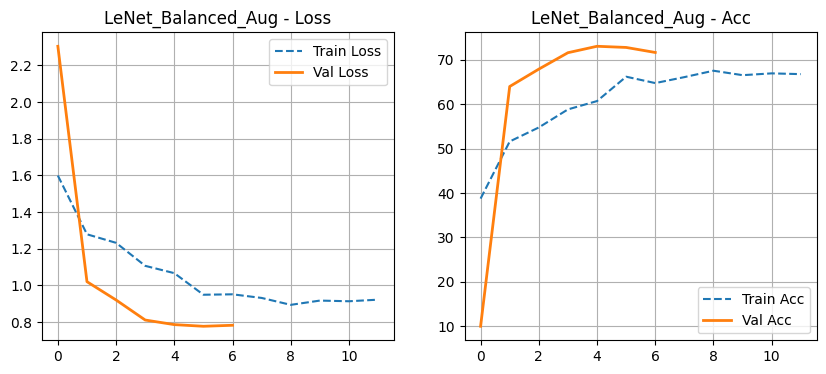


Top Results LeNet by Accuracy:
                     Model   H1   H2     BN    Aug   Opt Final Acc Final Loss
3       LeNet_Big_Adam_Aug  256  128   True   True  adam    74.47%     0.7280
5       LeNet_Balanced_Aug  120   84   True   True  adam    71.62%     0.7821
0    LeNet_Base_Adam_NoAug  120   84   True  False  adam    70.24%     0.9182
4       LeNet_Wide_SGD_Aug  512  256   True   True   sgd    69.82%     0.8824
1  LeNet_SGD_Classic_NoAug  120   84   True  False   sgd    69.58%     0.8502
2    LeNet_Small_Reg_NoAug   64   32  False  False  adam    52.98%     1.2695


In [35]:
import torch
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt
import copy

experiments_lenet = [
    {
        "name": "LeNet_Base_Adam_NoAug",
        "hidden_size1": 120,
        "hidden_size2": 84,
        "dropout_val": 0.5,
        "use_batch_norm": True,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "LeNet_SGD_Classic_NoAug",
        "hidden_size1": 120,
        "hidden_size2": 84,
        "dropout_val": 0.4,
        "use_batch_norm": True,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": False
    },
    {
        "name": "LeNet_Small_Reg_NoAug",
        "hidden_size1": 64,
        "hidden_size2": 32,
        "dropout_val": 0.3,
        "use_batch_norm": False,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "LeNet_Big_Adam_Aug",
        "hidden_size1": 256,
        "hidden_size2": 128,
        "dropout_val": 0.3,
        "use_batch_norm": True,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": True
    },
    {
        "name": "LeNet_Wide_SGD_Aug",
        "hidden_size1": 512,
        "hidden_size2": 256,
        "dropout_val": 0.4,
        "use_batch_norm": True,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": True
    },
    {
        "name": "LeNet_Balanced_Aug",
        "hidden_size1": 120,
        "hidden_size2": 84,
        "dropout_val": 0.2,
        "use_batch_norm": True,
        "lr": 0.0005,
        "optimizer": "adam",
        "augmentation": True
    }
]

best_acc_lenet = 0.0
best_model_name_lenet = None
best_config_lenet = {}
all_results_lenet = []

for exp in experiments_lenet:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = LeNet(img_size=64, num_classes=10, hidden_size1=exp['hidden_size1'], hidden_size2=exp['hidden_size2'],
                use_batch_norm=exp['use_batch_norm'], dropout_val=exp['dropout_val']).to(device)

    if exp['augmentation']:
        current_train_loader = train_land_loader_aug
        num_epochs = 40
    else:
        current_train_loader = train_land_loader
        num_epochs = 20

    if exp['optimizer'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=1e-4)

    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

    hist = train_engine_land(net=net, train_data_loader=current_train_loader, val_data_loader=val_land_loader,
                             optimizer=optimizer, scheduler=scheduler, num_epochs=num_epochs, name="Validation")

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    if torch.is_tensor(final_acc): final_acc = final_acc.item()
    if torch.is_tensor(final_loss): final_loss = final_loss.item()

    all_results_lenet.append({
        "Model": exp['name'],
        "H1": exp['hidden_size1'],
        "H2": exp['hidden_size2'],
        "BN": exp['use_batch_norm'],
        "Aug": exp['augmentation'],
        "Opt": exp['optimizer'],
        "Final Acc": final_acc,
        "Final Loss": final_loss
    })

    if final_acc > best_acc_lenet:
        best_acc_lenet = final_acc
        best_config_lenet = exp.copy()
        best_model_name_lenet = exp['name']

if all_results_lenet:
    df_lenet = pd.DataFrame(all_results_lenet)

    df_display = df_lenet.copy()
    df_display['Final Acc'] = df_display['Final Acc'].apply(lambda x: f"{x:.2f}%")
    df_display['Final Loss'] = df_display['Final Loss'].apply(lambda x: f"{x:.4f}")

    print("\nTop Results LeNet by Accuracy:")
    print(df_display.sort_values(by='Final Acc', ascending=False).head(6))

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


>>> [Test Test] Loss: 2.30122, Acc: 14.12%
[Test] [Ep: 4, Step: 99] Train Loss: 1.61758, Acc: 37.55%
[Test] [Ep: 7, Step: 199] Train Loss: 1.33967, Acc: 48.41%
>>> [Test Test] Loss: 1.23340, Acc: 50.59%
[Test] [Ep: 10, Step: 299] Train Loss: 1.21419, Acc: 54.64%
[Test] [Ep: 13, Step: 399] Train Loss: 1.09324, Acc: 59.52%
>>> [Test Test] Loss: 1.20904, Acc: 55.39%
[Test] [Ep: 16, Step: 499] Train Loss: 1.04540, Acc: 61.45%
[Test] [Ep: 19, Step: 599] Train Loss: 0.90816, Acc: 67.45%
>>> [Test Test] Loss: 0.80784, Acc: 71.41%
[Test] [Ep: 22, Step: 699] Train Loss: 0.90514, Acc: 67.17%
[Test] [Ep: 25, Step: 799] Train Loss: 0.89222, Acc: 67.84%
>>> [Test Test] Loss: 0.78138, Acc: 71.76%
[Test] [Ep: 29, Step: 899] Train Loss: 0.87048, Acc: 68.47%
[Test] [Ep: 32, Step: 999] Train Loss: 0.87282, Acc: 68.41%
>>> [Test Test] Loss: 0.77692, Acc: 72.12%
[Test] [Ep: 35, Step: 1099] Train Loss: 0.86296, Acc: 68.19%
[Test] [Ep: 38, Step: 1199] Train Loss: 0.85256, Acc: 68.73%
>>> [Test Test] Loss: 0

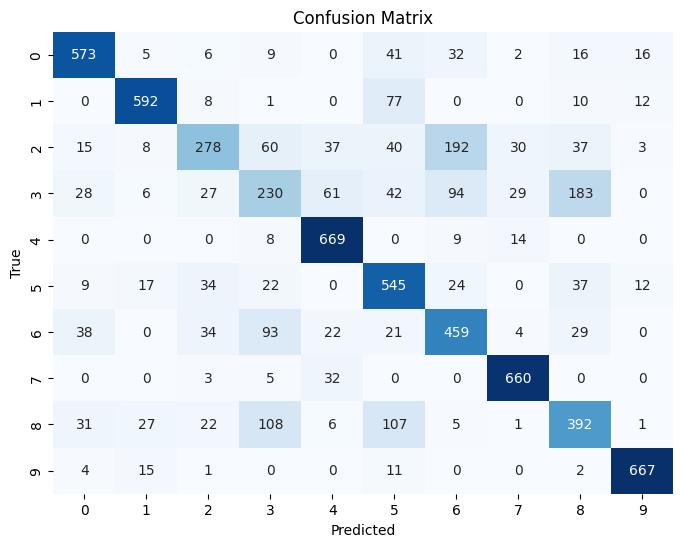

In [37]:
import torch.optim as optim

p = best_config_lenet

if p['augmentation']:
    final_train_loader = train_land_loader_aug
    final_epochs = 40
else:
    final_train_loader = train_land_loader
    final_epochs = 20

net = LeNet(img_size=64, num_classes=10, hidden_size1=p['hidden_size1'], hidden_size2=p['hidden_size2'],
            use_batch_norm=p['use_batch_norm'], dropout_val=p['dropout_val']).to(device)

if p['optimizer'] == 'sgd':
    optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)
else:
    optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

hist = train_engine_land(net=net, train_data_loader=final_train_loader, val_data_loader=test_land_loader,
                         optimizer=optimizer, scheduler=scheduler, num_epochs=final_epochs,
                         name="Test")

all_preds = []
all_labels = []

net.eval()
with torch.no_grad():
    for images, labels in test_land_loader:
        images = images.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


>>> [Source_ImageBits_Training Val] Loss: 2.30273, Acc: 10.05%
[Source_ImageBits_Training] [Ep: 1, Step: 99] Train Loss: 2.05138, Acc: 23.47%
[Source_ImageBits_Training] [Ep: 2, Step: 199] Train Loss: 1.72408, Acc: 32.36%
>>> [Source_ImageBits_Training Val] Loss: 1.47929, Acc: 45.20%
[Source_ImageBits_Training] [Ep: 3, Step: 299] Train Loss: 1.58510, Acc: 38.78%
[Source_ImageBits_Training] [Ep: 4, Step: 399] Train Loss: 1.51090, Acc: 42.66%
>>> [Source_ImageBits_Training Val] Loss: 1.26178, Acc: 53.55%
[Source_ImageBits_Training] [Ep: 4, Step: 499] Train Loss: 1.37904, Acc: 48.62%
[Source_ImageBits_Training] [Ep: 5, Step: 599] Train Loss: 1.30317, Acc: 52.33%
>>> [Source_ImageBits_Training Val] Loss: 1.12210, Acc: 59.17%
[Source_ImageBits_Training] [Ep: 6, Step: 699] Train Loss: 1.21883, Acc: 55.86%
[Source_ImageBits_Training] [Ep: 7, Step: 799] Train Loss: 1.17577, Acc: 57.42%
>>> [Source_ImageBits_Training Val] Loss: 1.18841, Acc: 56.66%
[Source_ImageBits_Training] [Ep: 8, Step: 899]

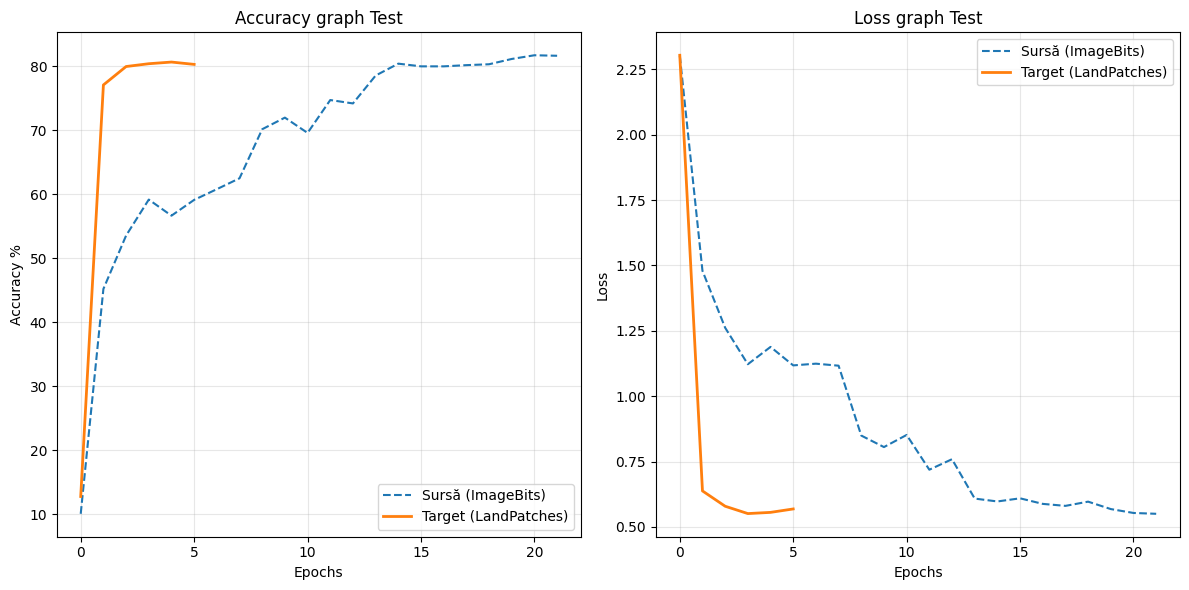

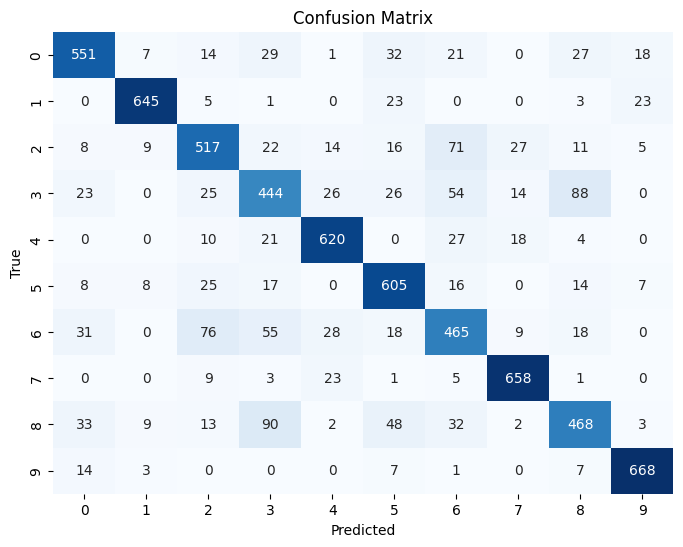


Final Result on LandPatches: 80.31% Accuracy


In [38]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

source_config = {
    "input": 512,
    "hidden1": 1024,
    "hidden2": 512,
    "batch_norm": True,
    "dropout_val": 0.5
}

source_net = MiniVGG(num_classes=10, in_size=source_config['input'], hidden_size1=source_config['hidden1'], hidden_size2=source_config['hidden2'], use_batch_norm=source_config['batch_norm'],dropout_val=source_config['dropout_val']).to(device)
optimizer_source = optim.Adam(source_net.parameters(), lr=0.0001, weight_decay=0.001)
scheduler_source = optim.lr_scheduler.MultiStepLR(optimizer_source, milestones=[20, 30], gamma=0.1)

hist_source = train_engine(net=source_net, train_data_loader=train_loader_aug, optimizer=optimizer_source,
                           scheduler=scheduler_source, num_epochs=35, name="Source_ImageBits_Training")

best_source_weights = copy.deepcopy(source_net.state_dict())
target_net = MiniVGG(num_classes=10, in_size=source_config['input'], hidden_size1=source_config['hidden1'],
                     hidden_size2=source_config['hidden2'], use_batch_norm=source_config['batch_norm'],
                     dropout_val=source_config['dropout_val']).to(device)

target_net.load_state_dict(best_source_weights)
for name, param in target_net.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

num_ftrs = target_net.fc3.in_features
target_net.fc3 = nn.Linear(num_ftrs, 10).to(device)

params_to_update = [p for p in target_net.parameters() if p.requires_grad]

optimizer_target = optim.Adam(params_to_update, lr=0.0001, weight_decay=0.001)
scheduler_target = optim.lr_scheduler.MultiStepLR(optimizer_target, milestones=[10, 15], gamma=0.1)

hist_transfer = train_engine_land(net=target_net, train_data_loader=train_land_loader, val_data_loader=test_land_loader,
                                  optimizer=optimizer_target, scheduler=scheduler_target, num_epochs=35,
                                  name="Test")

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(hist_source['val_acc'], label='Sursă (ImageBits)', linestyle='--')
plt.plot(hist_transfer['val_acc'], label='Target (LandPatches)', linewidth=2)
plt.title("Accuracy graph Test")
plt.xlabel("Epochs")
plt.ylabel("Accuracy %")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(hist_source['val_loss'], label='Sursă (ImageBits)', linestyle='--')
plt.plot(hist_transfer['val_loss'], label='Target (LandPatches)', linewidth=2)
plt.title("Loss graph Test")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

all_preds = []
all_labels = []

target_net.eval()
with torch.no_grad():
    for images, labels in test_land_loader:
        images = images.to(device)
        outputs = target_net(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

print(f"\nFinal Result on LandPatches: {hist_transfer['val_acc'][-1]:.2f}% Accuracy")